In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../data/raw/credit_risk_dataset.csv")

df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.shape

(32581, 12)

In [4]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [6]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(165)

In [8]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

In [9]:
df["loan_status"].value_counts(normalize=True) * 100

loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

In [10]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [11]:
df.describe(include="object")

C:\Users\sumit\AppData\Local\Temp\ipykernel_2200\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


In [12]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())

C:\Users\sumit\AppData\Local\Temp\ipykernel_2200\1789254986.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns



person_home_ownership
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


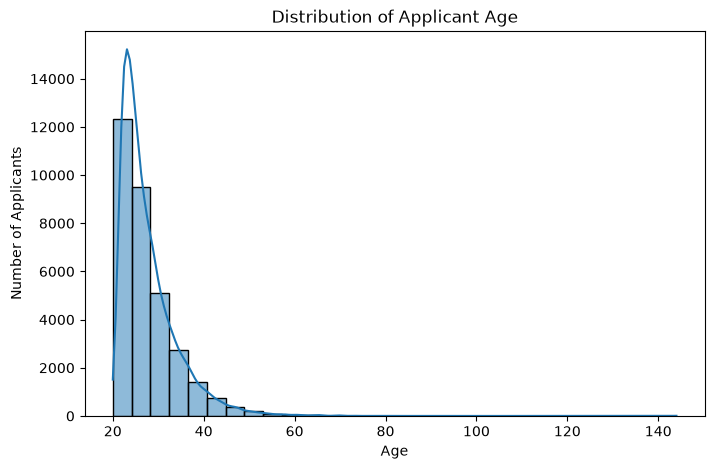

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="person_age", bins=30, kde=True)

plt.title("Distribution of Applicant Age")
plt.xlabel("Age")
plt.ylabel("Number of Applicants")

plt.show()

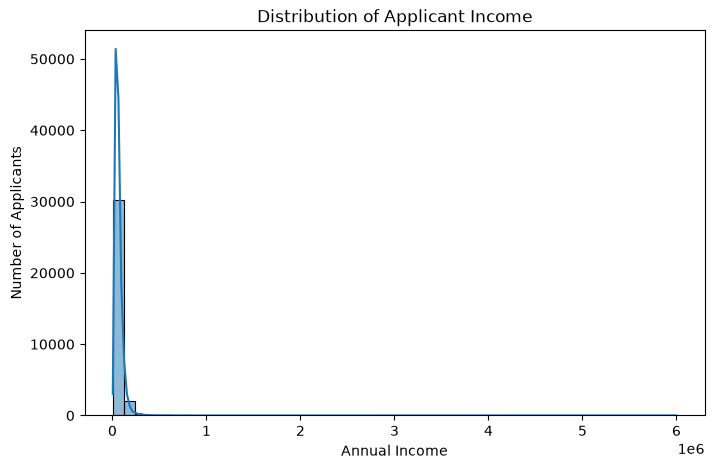

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="person_income", bins=50, kde=True)

plt.title("Distribution of Applicant Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Applicants")

plt.show()

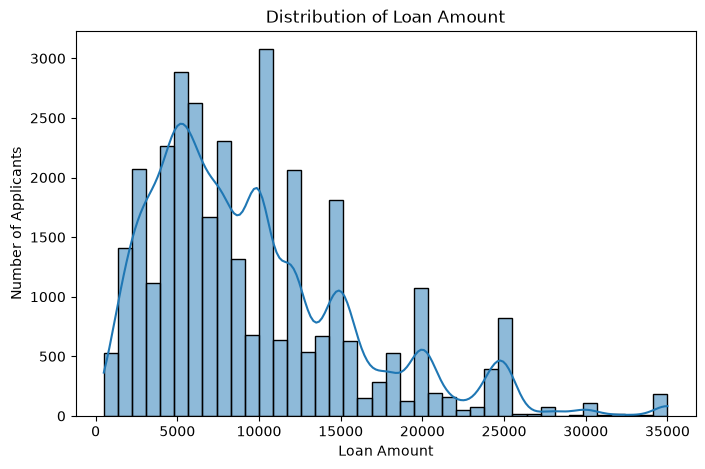

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="loan_amnt", bins=40, kde=True)

plt.title("Distribution of Loan Amount")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applicants")

plt.show()

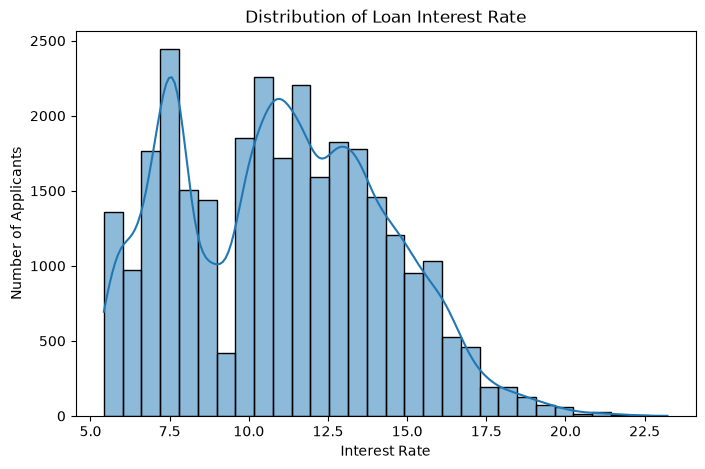

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="loan_int_rate", bins=30, kde=True)

plt.title("Distribution of Loan Interest Rate")
plt.xlabel("Interest Rate")
plt.ylabel("Number of Applicants")

plt.show()

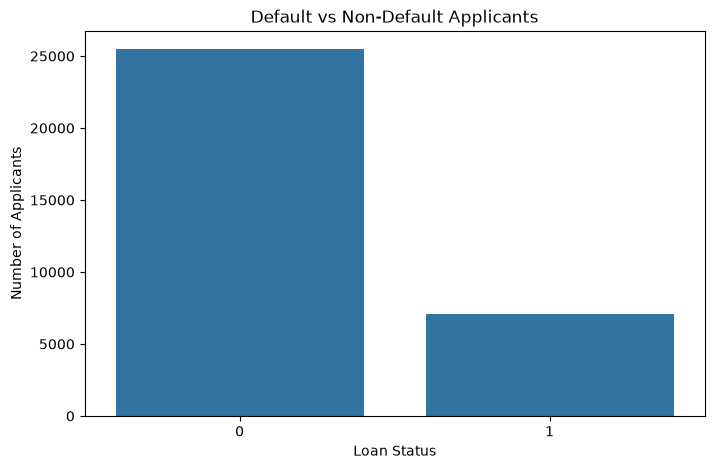

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="loan_status")

plt.title("Default vs Non-Default Applicants")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

In [18]:
default_by_grade = (
    df.groupby("loan_grade")["loan_status"]
    .mean()
    .sort_index()
)

default_by_grade

loan_grade
A    0.099564
B    0.162760
C    0.207340
D    0.590458
E    0.644191
F    0.705394
G    0.984375
Name: loan_status, dtype: float64

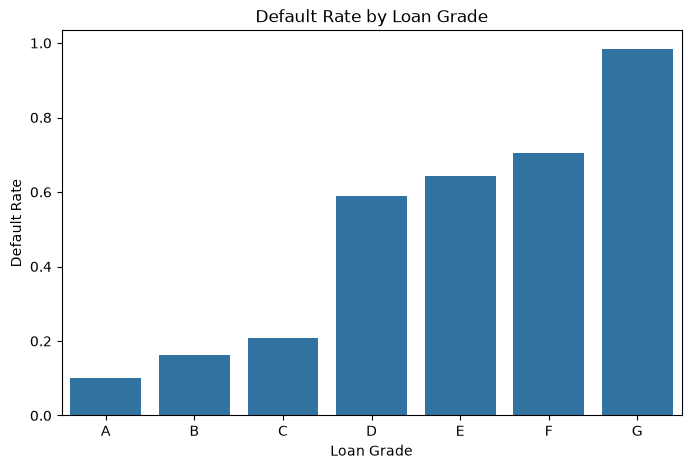

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=default_by_grade.index,
    y=default_by_grade.values
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate")

plt.show()

In [20]:
default_by_intent = (
    df.groupby("loan_intent")["loan_status"]
    .mean()
    .sort_values(ascending=False)
)

default_by_intent

loan_intent
DEBTCONSOLIDATION    0.285879
MEDICAL              0.267007
HOMEIMPROVEMENT      0.261026
PERSONAL             0.198877
EDUCATION            0.172168
VENTURE              0.148103
Name: loan_status, dtype: float64

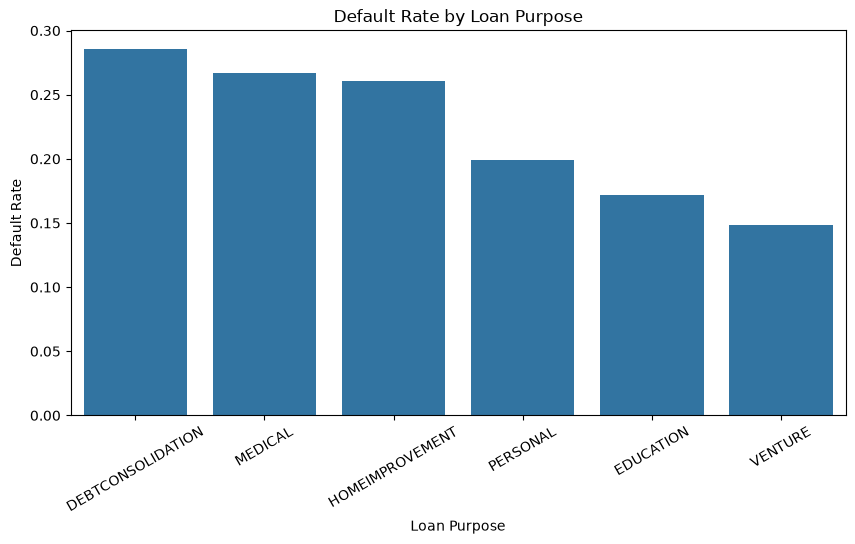

In [21]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=default_by_intent.index,
    y=default_by_intent.values
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate")

plt.xticks(rotation=30)

plt.show()

In [22]:
default_by_home = (
    df.groupby("person_home_ownership")["loan_status"]
    .mean()
    .sort_values(ascending=False)
)

default_by_home

person_home_ownership
RENT        0.315700
OTHER       0.308411
MORTGAGE    0.125707
OWN         0.074690
Name: loan_status, dtype: float64

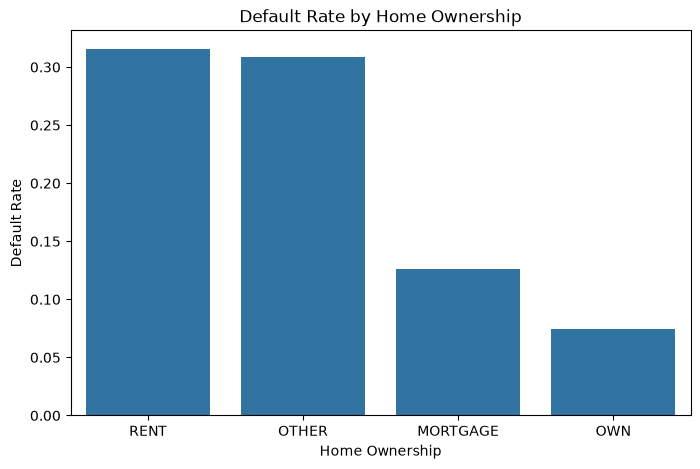

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=default_by_home.index,
    y=default_by_home.values
)

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate")

plt.show()

In [24]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [25]:
df.describe(include="object")

C:\Users\sumit\AppData\Local\Temp\ipykernel_2200\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


In [26]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())

C:\Users\sumit\AppData\Local\Temp\ipykernel_2200\1789254986.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns



person_home_ownership
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


In [27]:
default_by_grade = df.groupby("loan_grade")["loan_status"].mean()
default_by_grade

loan_grade
A    0.099564
B    0.162760
C    0.207340
D    0.590458
E    0.644191
F    0.705394
G    0.984375
Name: loan_status, dtype: float64

In [28]:
default_by_intent = df.groupby("loan_intent")["loan_status"].mean()
default_by_intent

loan_intent
DEBTCONSOLIDATION    0.285879
EDUCATION            0.172168
HOMEIMPROVEMENT      0.261026
MEDICAL              0.267007
PERSONAL             0.198877
VENTURE              0.148103
Name: loan_status, dtype: float64

In [29]:
df[df["person_age"] > 80]["person_age"].value_counts().sort_index()

person_age
84     1
94     1
123    2
144    3
Name: count, dtype: int64

In [30]:
df["person_age"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

0.900    36.0
0.950    40.0
0.990    50.0
0.995    54.0
0.999    66.0
Name: person_age, dtype: float64

In [31]:
df["person_income"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

0.900    110004.0
0.950    138000.0
0.990    225200.0
0.995    300000.0
0.999    648000.0
Name: person_income, dtype: float64

In [32]:
df[df.duplicated(keep=False)].shape

(330, 12)

In [33]:
missing = df.isnull().sum()

missing_percentage = (
    missing / len(df) * 100
).sort_values(ascending=False)

missing_percentage

loan_int_rate                 9.563856
person_emp_length             2.747000
person_income                 0.000000
person_age                    0.000000
person_home_ownership         0.000000
loan_intent                   0.000000
loan_grade                    0.000000
loan_amnt                     0.000000
loan_status                   0.000000
loan_percent_income           0.000000
cb_person_default_on_file     0.000000
cb_person_cred_hist_length    0.000000
dtype: float64

In [34]:
pd.crosstab(
    df["cb_person_default_on_file"],
    df["loan_status"],
    normalize="index"
) * 100

loan_status,0,1
cb_person_default_on_file,,
N,81.606797,18.393203
Y,62.193211,37.806789


In [35]:
df[df["person_age"] > 80][
    ["person_age", "person_income", "person_home_ownership",
     "person_emp_length", "loan_intent", "loan_grade",
     "loan_amnt", "loan_status"]
].sort_values("person_age")

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_status
32506,84,94800,MORTGAGE,2.0,PERSONAL,A,10000,0
32416,94,24000,RENT,1.0,MEDICAL,C,6500,0
747,123,78000,RENT,7.0,VENTURE,B,20000,0
575,123,80004,RENT,2.0,EDUCATION,B,20400,0
81,144,250000,RENT,4.0,VENTURE,C,4800,0
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,0
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,0


In [36]:
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.groupby(list(df.columns)).size().sort_values(ascending=False).head(20)

person_age  person_income  person_home_ownership  person_emp_length  loan_intent        loan_grade  loan_amnt  loan_int_rate  loan_status  loan_percent_income  cb_person_default_on_file  cb_person_cred_hist_length
21          15600          RENT                   0.0                MEDICAL            A           2800       7.40           1            0.18                 N                          4                             2
            18000          RENT                   0.0                DEBTCONSOLIDATION  A           3000       7.90           1            0.17                 N                          2                             2
            26000          RENT                   5.0                DEBTCONSOLIDATION  A           6000       7.49           0            0.23                 N                          2                             2
            26400          RENT                   5.0                PERSONAL           C           4750       12.23          0  

In [37]:
# Number of rows involved in exact duplicates
duplicate_rows_count = df.duplicated(keep=False).sum()

# Number of unique records that are duplicated
duplicate_groups_count = (
    df[df.duplicated(keep=False)]
    .drop_duplicates()
    .shape[0]
)

print("Rows involved in duplicates:", duplicate_rows_count)
print("Unique duplicated records:", duplicate_groups_count)

Rows involved in duplicates: 330
Unique duplicated records: 165


In [38]:
# How many times are the duplicated records repeated?
duplicate_frequency = (
    df.value_counts()
    .loc[lambda x: x > 1]
    .value_counts()
    .sort_index()
)

duplicate_frequency

count
2    137
Name: count, dtype: int64

In [39]:
# Complete distribution of duplicate frequencies

duplicate_frequency = (
    df.value_counts()
      .loc[lambda x: x > 1]
      .value_counts()
      .sort_index()
)

duplicate_frequency

count
2    137
Name: count, dtype: int64

In [40]:
duplicate_counts = (
    df[df.duplicated(keep=False)]
    .groupby(list(df.columns))
    .size()
    .value_counts()
    .sort_index()
)

duplicate_counts

2    137
Name: count, dtype: int64

In [41]:
duplicate_groups = (
    df[df.duplicated(keep=False)]
    .groupby(list(df.columns))
    .size()
)

print("Unique duplicated records:", len(duplicate_groups))
print("Rows involved in duplicates:", duplicate_groups.sum())
print("Duplicate frequency distribution:")
print(duplicate_groups.value_counts().sort_index())

Unique duplicated records: 137
Rows involved in duplicates: 274
Duplicate frequency distribution:
2    137
Name: count, dtype: int64


In [42]:
duplicate_groups = (
    df[df.duplicated(keep=False)]
    .groupby(list(df.columns), dropna=False)
    .size()
)

print("Unique duplicated records:", len(duplicate_groups))
print("Rows involved in duplicates:", duplicate_groups.sum())

print("\nDuplicate frequency distribution:")
print(duplicate_groups.value_counts().sort_index())

Unique duplicated records: 165
Rows involved in duplicates: 330

Duplicate frequency distribution:
2    165
Name: count, dtype: int64


In [43]:
duplicate_groups[duplicate_groups > 2].sort_values(ascending=False)

Series([], dtype: int64)

In [44]:
duplicate_groups[duplicate_groups == 2].shape[0]

165

In [45]:
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.isna().sum().sort_values(ascending=False)

loan_int_rate                 42
person_emp_length             16
person_income                  0
person_age                     0
person_home_ownership          0
loan_intent                    0
loan_grade                     0
loan_amnt                      0
loan_status                    0
loan_percent_income            0
cb_person_default_on_file      0
cb_person_cred_hist_length     0
dtype: int64

In [46]:
duplicate_rows["loan_status"].value_counts(normalize=True) * 100

loan_status
0    88.484848
1    11.515152
Name: proportion, dtype: float64

In [47]:
print("Overall target distribution:")
print(df["loan_status"].value_counts(normalize=True) * 100)

print("\nTarget distribution among duplicated rows:")
print(duplicate_rows["loan_status"].value_counts(normalize=True) * 100)

Overall target distribution:
loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

Target distribution among duplicated rows:
loan_status
0    88.484848
1    11.515152
Name: proportion, dtype: float64


In [48]:
print("Original dataset shape:", df.shape)

df_unique = df.drop_duplicates()

print("After removing exact duplicates:", df_unique.shape)

print("\nRows removed:", len(df) - len(df_unique))

Original dataset shape: (32581, 12)
After removing exact duplicates: (32416, 12)

Rows removed: 165


In [49]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_unique.shape)

print("\nRemaining exact duplicates:")
print(df_unique.duplicated().sum())

print("\nTarget distribution after deduplication:")
print(df_unique["loan_status"].value_counts(normalize=True) * 100)

Original shape: (32581, 12)
Cleaned shape: (32416, 12)

Remaining exact duplicates:
0

Target distribution after deduplication:
loan_status
0    78.13117
1    21.86883
Name: proportion, dtype: float64


In [50]:
df_unique[df_unique["person_age"] > 80][
    [
        "person_age",
        "person_income",
        "person_home_ownership",
        "person_emp_length",
        "loan_intent",
        "loan_grade",
        "loan_amnt",
        "loan_int_rate",
        "loan_status",
        "cb_person_default_on_file",
        "cb_person_cred_hist_length"
    ]
].sort_values("person_age")

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,cb_person_default_on_file,cb_person_cred_hist_length
32506,84,94800,MORTGAGE,2.0,PERSONAL,A,10000,7.51,0,N,24
32416,94,24000,RENT,1.0,MEDICAL,C,6500,NaN,0,N,27
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,N,4
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,N,3
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,N,2
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,N,25


In [51]:
df_unique[df_unique["person_age"] > 80][
    ["person_age", "cb_person_cred_hist_length", "person_income", "loan_status"]
].sort_values("person_age")

,person_age,cb_person_cred_hist_length,person_income,loan_status
32506,84,24,94800,0
32416,94,27,24000,0
747,123,4,78000,0
575,123,3,80004,0
81,144,3,250000,0
183,144,2,200000,0
32297,144,25,6000000,0


In [52]:
df_unique["person_age"].describe(percentiles=[
    0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
])

count    32416.000000
mean        27.747008
std          6.354100
min         20.000000
1%          21.000000
5%          22.000000
10%         22.000000
25%         23.000000
50%         26.000000
75%         30.000000
90%         36.000000
95%         40.000000
99%         50.000000
max        144.000000
Name: person_age, dtype: float64

In [53]:
df_unique["person_age"].value_counts().sort_index().tail(30)

person_age
48     75
49     48
50     52
51     39
52     36
53     30
54     24
55     20
56     15
57     15
58     19
59      5
60     15
61      9
62      7
63      3
64      7
65      9
66      9
67      1
69      5
70      7
73      3
76      1
78      1
80      1
84      1
94      1
123     2
144     3
Name: count, dtype: int64

In [54]:
df_unique.groupby("person_age")["cb_person_cred_hist_length"].agg(
    ["count", "min", "median", "max"]
).tail(30)

,count,min,median,max
person_age,,,,
48,75,11,14.0,17
49,48,11,14.0,17
50,52,11,14.0,17
51,39,18,23.0,30
52,36,18,24.0,30
53,30,18,25.5,30
54,24,18,21.0,29
55,20,18,26.0,30
56,15,18,21.0,28


In [55]:
df_unique[df_unique["person_age"] >= 123][
    [
        "person_age",
        "cb_person_cred_hist_length",
        "person_income",
        "person_home_ownership",
        "person_emp_length",
        "loan_intent",
        "loan_grade",
        "loan_amnt",
        "loan_int_rate",
        "loan_status"
    ]
].sort_values("person_age")

,person_age,cb_person_cred_hist_length,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status
747,123,4,78000,RENT,7.0,VENTURE,B,20000,NaN,0
575,123,3,80004,RENT,2.0,EDUCATION,B,20400,10.25,0
183,144,2,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0
81,144,3,250000,RENT,4.0,VENTURE,C,4800,13.57,0
32297,144,25,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0


In [56]:
df_unique[df_unique["person_age"] >= 123].shape

(5, 12)

In [57]:
# Remove clearly invalid age records (123 and 144)
df_clean = df_unique[df_unique["person_age"] < 123].copy()

print("Before age cleaning:", df_unique.shape)
print("After age cleaning:", df_clean.shape)
print("Rows removed:", len(df_unique) - len(df_clean))

Before age cleaning: (32416, 12)
After age cleaning: (32411, 12)
Rows removed: 5


In [58]:
df_clean["person_age"].describe()

count    32411.000000
mean        27.730369
std          6.210448
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max         94.000000
Name: person_age, dtype: float64

In [59]:
df_clean["person_age"].value_counts().sort_index().tail(15)

person_age
61    9
62    7
63    3
64    7
65    9
66    9
67    1
69    5
70    7
73    3
76    1
78    1
80    1
84    1
94    1
Name: count, dtype: int64

In [60]:
df_clean["person_income"].describe(
    percentiles=[
        0.90,
        0.95,
        0.99,
        0.995,
        0.999
    ]
)

count    3.241100e+04
mean     6.589796e+04
std      5.252093e+04
min      4.000000e+03
90%      1.100040e+05
95%      1.380000e+05
99%      2.250000e+05
99.5%    3.000000e+05
99.9%    6.430800e+05
max      2.039784e+06
Name: person_income, dtype: float64

In [61]:
df_clean["person_income"].sort_values().tail(30)

29128     700000
25714     703800
29126     708000
32543     720000
27882     741600
27883     750000
28253     762000
27884     762000
31916     780000
30536     780000
32551     780000
32070     780000
32544     780000
31918     800000
31919     828000
32037     828000
29345     889000
31921     900000
29121     900000
29122     900000
32298     900000
17834     948000
17833    1200000
29120    1200000
29119    1200000
31922    1362000
31924    1440000
32497    1782000
32546    1900000
30049    2039784
Name: person_income, dtype: int64

In [62]:
df_clean[df_clean["person_income"] > 500000][
    [
        "person_age",
        "person_income",
        "person_home_ownership",
        "person_emp_length",
        "loan_intent",
        "loan_grade",
        "loan_amnt",
        "loan_int_rate",
        "loan_status"
    ]
].sort_values("person_income", ascending=False)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status
30049,42,2039784,RENT,0.0,VENTURE,C,8450,12.29,0
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,NaN,0
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0
31924,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.40,0
31922,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.74,0
29119,36,1200000,OWN,16.0,MEDICAL,A,10000,6.54,0
29120,40,1200000,MORTGAGE,1.0,MEDICAL,A,10000,NaN,0
17833,32,1200000,MORTGAGE,1.0,VENTURE,A,12000,7.51,0
17834,34,948000,MORTGAGE,18.0,PERSONAL,B,2000,9.99,0
29121,50,900000,MORTGAGE,11.0,DEBTCONSOLIDATION,B,30000,12.69,0


In [63]:
missing_cols = ["loan_int_rate", "person_emp_length"]

for col in missing_cols:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print(f"{'='*50}")
    
    print("Missing count:")
    print(df_clean[col].isna().sum())
    
    print("\nTarget distribution among missing values:")
    print(
        df_clean.loc[df_clean[col].isna(), "loan_status"]
        .value_counts(normalize=True) * 100
    )
    
    print("\nTarget distribution among non-missing values:")
    print(
        df_clean.loc[df_clean[col].notna(), "loan_status"]
        .value_counts(normalize=True) * 100
    )


Column: loan_int_rate
Missing count:
3094

Target distribution among missing values:
loan_status
0    79.282482
1    20.717518
Name: proportion, dtype: float64

Target distribution among non-missing values:
loan_status
0    78.005935
1    21.994065
Name: proportion, dtype: float64

Column: person_emp_length
Missing count:
887

Target distribution among missing values:
loan_status
0    68.32018
1    31.67982
Name: proportion, dtype: float64

Target distribution among non-missing values:
loan_status
0    78.403756
1    21.596244
Name: proportion, dtype: float64


In [64]:
for col in missing_cols:
    print(f"\n{col}")
    print(
        df_clean.groupby(df_clean[col].isna())["loan_status"]
        .value_counts(normalize=True)
        .unstack(fill_value=0) * 100
    )


loan_int_rate
loan_status            0          1
loan_int_rate                      
False          78.005935  21.994065
True           79.282482  20.717518

person_emp_length
loan_status                0          1
person_emp_length                      
False              78.403756  21.596244
True               68.320180  31.679820


In [65]:
for col in missing_cols:
    print(f"\n{'='*60}")
    print(f"Missingness by loan grade: {col}")
    print(f"{'='*60}")
    
    print(
        df_clean.groupby("loan_grade")[col]
        .apply(lambda x: x.isna().mean() * 100)
        .sort_values(ascending=False)
    )


Missingness by loan grade: loan_int_rate
loan_grade
F    11.203320
B    10.102080
C     9.773151
A     9.249743
E     8.618899
D     8.591160
G     7.812500
Name: loan_int_rate, dtype: float64

Missingness by loan grade: person_emp_length
loan_grade
A    3.755956
B    2.532743
C    2.097576
F    2.074689
D    1.933702
E    1.246106
G    0.000000
Name: person_emp_length, dtype: float64


In [66]:
for col in missing_cols:
    print(f"\n{'='*60}")
    print(f"Missingness by age group: {col}")
    print(f"{'='*60}")
    
    age_group = pd.cut(
        df_clean["person_age"],
        bins=[19, 25, 35, 45, 55, 65, 100],
        labels=["20-25", "26-35", "36-45", "46-55", "56-65", "66+"]
    )
    
    print(
        df_clean.groupby(age_group, observed=False)[col]
        .apply(lambda x: x.isna().mean() * 100)
    )


Missingness by age group: loan_int_rate
person_age
20-25     9.406363
26-35     9.423091
36-45    10.430758
46-55    11.914062
56-65     9.615385
66+      13.333333
Name: loan_int_rate, dtype: float64

Missingness by age group: person_emp_length
person_age
20-25    2.978026
26-35    2.516228
36-45    2.776789
46-55    1.562500
56-65    0.961538
66+      3.333333
Name: person_emp_length, dtype: float64


In [67]:
print("Employment length distribution among non-missing values:")

df_clean["person_emp_length"].describe()

Employment length distribution among non-missing values:


count    31524.000000
mean         4.790350
std          4.145566
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max        123.000000
Name: person_emp_length, dtype: float64

In [68]:
df_clean[df_clean["person_emp_length"] > 40][
    [
        "person_age",
        "person_emp_length",
        "person_income",
        "person_home_ownership",
        "loan_grade",
        "loan_amnt",
        "loan_status"
    ]
].sort_values("person_emp_length", ascending=False)

,person_age,person_emp_length,person_income,person_home_ownership,loan_grade,loan_amnt,loan_status
0,22,123.0,59000,RENT,D,35000,1
210,21,123.0,192000,MORTGAGE,A,20000,0
32355,78,41.0,48000,RENT,A,3000,0


In [69]:
df_clean[df_clean["person_emp_length"] > 20][
    [
        "person_age",
        "person_emp_length",
        "loan_grade",
        "loan_status"
    ]
].sort_values("person_emp_length", ascending=False)

,person_age,person_emp_length,loan_grade,loan_status
0,22,123.0,D,1
210,21,123.0,A,0
32355,78,41.0,A,0
32515,53,38.0,B,0
32428,58,34.0,D,1
...,...,...,...,...
32067,37,21.0,B,1
32055,37,21.0,A,0
31892,39,21.0,C,0
31968,37,21.0,B,0


In [70]:
df_clean["person_emp_length"].value_counts().sort_index().tail(20)

person_emp_length
16.0     165
17.0     128
18.0     104
19.0      64
20.0      42
21.0      38
22.0      19
23.0      10
24.0      10
25.0       8
26.0       6
27.0       5
28.0       3
29.0       1
30.0       2
31.0       4
34.0       1
38.0       1
41.0       1
123.0      2
Name: count, dtype: int64

In [71]:
invalid_emp = df_clean[
    df_clean["person_emp_length"] >
    (df_clean["person_age"] - 18)
]

invalid_emp[
    [
        "person_age",
        "person_emp_length",
        "person_income",
        "loan_grade",
        "loan_status"
    ]
].sort_values(
    ["person_age", "person_emp_length"],
    ascending=False
)

,person_age,person_emp_length,person_income,loan_grade,loan_status
32515,53,38.0,106000,B,0
30914,48,31.0,70000,D,0
31866,47,31.0,178000,B,0
31867,46,31.0,180000,B,0
32263,46,31.0,180000,B,0
...,...,...,...,...,...
16339,20,4.0,188004,A,0
17196,20,4.0,65000,B,0
1313,20,3.0,64000,D,1
7748,20,3.0,34800,C,0


In [72]:
print("Invalid employment-length records:", len(invalid_emp))

Invalid employment-length records: 7782


In [73]:
df_clean[df_clean["person_emp_length"] == 123][
    [
        "person_age",
        "person_emp_length",
        "person_income",
        "person_home_ownership",
        "loan_grade",
        "loan_amnt",
        "loan_status"
    ]
]

,person_age,person_emp_length,person_income,person_home_ownership,loan_grade,loan_amnt,loan_status
0,22,123.0,59000,RENT,D,35000,1
210,21,123.0,192000,MORTGAGE,A,20000,0


In [74]:
print(
    "Records with employment length = 123:",
    (df_clean["person_emp_length"] == 123).sum()
)

Records with employment length = 123: 2


In [75]:
df_clean = df_clean[df_clean["person_emp_length"] != 123].copy()

In [76]:
print("Shape after employment-length cleaning:", df_clean.shape)
print("Maximum employment length:", df_clean["person_emp_length"].max())

Shape after employment-length cleaning: (32409, 12)
Maximum employment length: 41.0


In [77]:
missing_emp = df_clean[df_clean["person_emp_length"].isna()].copy()

missing_emp[
    [
        "person_age",
        "person_income",
        "person_home_ownership",
        "loan_intent",
        "loan_grade",
        "loan_amnt",
        "loan_status"
    ]
].describe(include="all")

,person_age,person_income,person_home_ownership,loan_intent,loan_grade,loan_amnt,loan_status
count,887.000000,887.000000,887,887,887,887.000000,887.000000
unique,NaN,NaN,3,6,6,NaN,NaN
top,NaN,NaN,RENT,MEDICAL,A,NaN,NaN
freq,NaN,NaN,367,173,402,NaN,NaN
mean,27.312289,44308.392334,NaN,NaN,NaN,7059.188275,0.316798
std,5.897210,37472.609235,NaN,NaN,NaN,5208.977655,0.465490
min,21.000000,4200.000000,NaN,NaN,NaN,1000.000000,0.000000
25%,23.000000,24000.000000,NaN,NaN,NaN,3200.000000,0.000000
50%,25.000000,36000.000000,NaN,NaN,NaN,6000.000000,0.000000
75%,30.000000,55000.000000,NaN,NaN,NaN,9775.000000,1.000000


In [78]:
missing_emp[
    ["person_age", "person_income", "loan_amnt", "loan_status"]
].describe()

,person_age,person_income,loan_amnt,loan_status
count,887.000000,887.000000,887.000000,887.000000
mean,27.312289,44308.392334,7059.188275,0.316798
std,5.897210,37472.609235,5208.977655,0.465490
min,21.000000,4200.000000,1000.000000,0.000000
25%,23.000000,24000.000000,3200.000000,0.000000
50%,25.000000,36000.000000,6000.000000,0.000000
75%,30.000000,55000.000000,9775.000000,1.000000
max,70.000000,648000.000000,35000.000000,1.000000


In [79]:
df_clean.groupby(
    df_clean["person_emp_length"].isna()
)[
    ["person_age", "person_income", "loan_amnt", "loan_status"]
].median()

,person_age,person_income,loan_amnt,loan_status
person_emp_length,,,,
False,26.0,56000.0,8000.0,0.0
True,25.0,36000.0,6000.0,0.0


In [80]:
df_clean["age_group"] = pd.cut(
    df_clean["person_age"],
    bins=[19, 25, 35, 45, 55, 65, 100],
    labels=["20-25", "26-35", "36-45", "46-55", "56-65", "66+"]
)

df_clean.groupby("age_group")["person_emp_length"].apply(
    lambda x: x.isna().mean() * 100
).sort_values(ascending=False)

age_group
66+      3.333333
20-25    2.978416
36-45    2.776789
26-35    2.516228
46-55    1.562500
56-65    0.961538
Name: person_emp_length, dtype: float64

In [81]:
df_clean.groupby("age_group")["person_emp_length"].agg(
    ["count", "median", "mean", "min", "max"]
)

,count,median,mean,min,max
age_group,,,,,
20-25,14789,4.0,4.032592,0.0,10.0
26-35,13366,4.0,5.305551,0.0,19.0
36-45,2731,4.0,6.000366,0.0,28.0
46-55,504,4.0,6.017857,0.0,38.0
56-65,103,3.0,6.048544,0.0,34.0
66+,29,3.0,5.862069,0.0,41.0


In [82]:
df_clean.groupby("loan_grade")["person_emp_length"].agg(
    ["count", "median", "mean", "min", "max"]
)

,count,median,mean,min,max
loan_grade,,,,,
A,10300,4.0,5.093689,0.0,41.0
B,10121,4.0,4.754669,0.0,38.0
C,6301,4.0,4.451516,0.0,29.0
D,3549,4.0,4.672584,0.0,34.0
E,951,3.0,4.363828,0.0,22.0
F,236,3.0,4.254237,0.0,20.0
G,64,5.0,6.125000,0.0,18.0


In [83]:
missing_emp = df_clean[df_clean["person_emp_length"].isna()].copy()

missing_emp[
    ["person_age", "person_income", "loan_amnt", "loan_status"]
].describe()

,person_age,person_income,loan_amnt,loan_status
count,887.000000,887.000000,887.000000,887.000000
mean,27.312289,44308.392334,7059.188275,0.316798
std,5.897210,37472.609235,5208.977655,0.465490
min,21.000000,4200.000000,1000.000000,0.000000
25%,23.000000,24000.000000,3200.000000,0.000000
50%,25.000000,36000.000000,6000.000000,0.000000
75%,30.000000,55000.000000,9775.000000,1.000000
max,70.000000,648000.000000,35000.000000,1.000000


In [84]:
df_clean.groupby(
    df_clean["person_emp_length"].isna()
)[
    ["person_age", "person_income", "loan_amnt", "loan_status"]
].median()

,person_age,person_income,loan_amnt,loan_status
person_emp_length,,,,
False,26.0,56000.0,8000.0,0.0
True,25.0,36000.0,6000.0,0.0


In [85]:
df_clean.groupby("age_group")["person_emp_length"].apply(
    lambda x: x.isna().mean() * 100
).sort_values(ascending=False)

age_group
66+      3.333333
20-25    2.978416
36-45    2.776789
26-35    2.516228
46-55    1.562500
56-65    0.961538
Name: person_emp_length, dtype: float64

In [86]:
df_clean.groupby("age_group")["person_emp_length"].agg(
    ["count", "median", "mean", "min", "max"]
)

,count,median,mean,min,max
age_group,,,,,
20-25,14789,4.0,4.032592,0.0,10.0
26-35,13366,4.0,5.305551,0.0,19.0
36-45,2731,4.0,6.000366,0.0,28.0
46-55,504,4.0,6.017857,0.0,38.0
56-65,103,3.0,6.048544,0.0,34.0
66+,29,3.0,5.862069,0.0,41.0


In [87]:
df_clean["person_emp_length"].value_counts(
    dropna=False
).sort_index()

person_emp_length
0.0     4086
1.0     2897
2.0     3831
3.0     3442
4.0     2861
5.0     2926
6.0     2652
7.0     2185
8.0     1676
9.0     1359
10.0     692
11.0     735
12.0     570
13.0     426
14.0     334
15.0     238
16.0     165
17.0     128
18.0     104
19.0      64
20.0      42
21.0      38
22.0      19
23.0      10
24.0      10
25.0       8
26.0       6
27.0       5
28.0       3
29.0       1
30.0       2
31.0       4
34.0       1
38.0       1
41.0       1
NaN      887
Name: count, dtype: int64

In [88]:
df_clean["person_emp_length"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    31522.000000
mean         4.782850
std          4.037343
min          0.000000
1%           0.000000
5%           0.000000
10%          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
90%         10.000000
95%         13.000000
99%         18.000000
max         41.000000
Name: person_emp_length, dtype: float64

In [89]:
df_clean.loc[
    df_clean["person_emp_length"].isna(),
    "age_group"
].value_counts().sort_index()

age_group
20-25    454
26-35    345
36-45     78
46-55      8
56-65      1
66+        1
Name: count, dtype: int64

In [90]:
pd.crosstab(
    df_clean["age_group"],
    df_clean["person_emp_length"].isna(),
    normalize="index"
) * 100

person_emp_length,False,True
age_group,,
20-25,97.021584,2.978416
26-35,97.483772,2.516228
36-45,97.223211,2.776789
46-55,98.437500,1.562500
56-65,99.038462,0.961538
66+,96.666667,3.333333


In [91]:
# Store missing count before imputation
missing_before = df_clean["person_emp_length"].isna().sum()

# Age-group median imputation
age_median = df_clean.groupby("age_group")["person_emp_length"].transform("median")

df_clean["person_emp_length"] = (
    df_clean["person_emp_length"].fillna(age_median)
)

# Verify
missing_after = df_clean["person_emp_length"].isna().sum()

print("Missing before:", missing_before)
print("Missing after:", missing_after)
print("Values imputed:", missing_before - missing_after)

Missing before: 887
Missing after: 0
Values imputed: 887


In [92]:
# Check employment-length distribution after imputation

print("Employment length statistics after imputation:")
print(
    df_clean["person_emp_length"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nEmployment length value counts:")
print(
    df_clean["person_emp_length"]
    .value_counts()
    .sort_index()
)

Employment length statistics after imputation:
count    32409.000000
mean         4.761363
std          3.983777
min          0.000000
1%           0.000000
5%           0.000000
10%          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
90%         10.000000
95%         12.000000
99%         17.000000
max         41.000000
Name: person_emp_length, dtype: float64

Employment length value counts:
person_emp_length
0.0     4086
1.0     2897
2.0     3831
3.0     3444
4.0     3746
5.0     2926
6.0     2652
7.0     2185
8.0     1676
9.0     1359
10.0     692
11.0     735
12.0     570
13.0     426
14.0     334
15.0     238
16.0     165
17.0     128
18.0     104
19.0      64
20.0      42
21.0      38
22.0      19
23.0      10
24.0      10
25.0       8
26.0       6
27.0       5
28.0       3
29.0       1
30.0       2
31.0       4
34.0       1
38.0       1
41.0       1
Name: count, dtype: int64


In [93]:
df_clean.groupby("loan_grade")["loan_int_rate"].agg(
    ["count", "median", "mean", "min", "max"]
).sort_index()

,count,median,mean,min,max
loan_grade,,,,,
A,9712,7.490,7.328504,5.42,9.63
B,9335,10.990,10.995743,6.00,12.69
C,5807,13.480,13.464687,6.00,16.11
D,3308,15.310,15.360499,6.00,18.49
E,880,16.820,17.008409,6.00,20.69
F,214,18.535,18.609159,15.01,22.06
G,59,20.160,20.251525,17.34,23.22


In [94]:
pd.crosstab(
    df_clean["loan_grade"],
    df_clean["loan_int_rate"].isna(),
    normalize="index"
) * 100

loan_int_rate,False,True
loan_grade,,
A,90.749393,9.250607
B,89.897920,10.102080
C,90.226849,9.773151
D,91.406466,8.593534
E,91.381101,8.618899
F,88.796680,11.203320
G,92.187500,7.812500


In [95]:
pd.crosstab(
    df_clean["loan_int_rate"].isna(),
    df_clean["loan_status"],
    normalize="index"
) * 100

loan_status,0,1
loan_int_rate,,
False,78.007846,21.992154
True,79.282482,20.717518


In [96]:
# Store missing count before imputation
missing_before = df_clean["loan_int_rate"].isna().sum()

# Calculate median interest rate for each loan grade
grade_median = df_clean.groupby("loan_grade")["loan_int_rate"].transform("median")

# Fill missing values using the corresponding loan-grade median
df_clean["loan_int_rate"] = (
    df_clean["loan_int_rate"].fillna(grade_median)
)

# Verify
missing_after = df_clean["loan_int_rate"].isna().sum()

print("Missing before:", missing_before)
print("Missing after:", missing_after)
print("Values imputed:", missing_before - missing_after)

Missing before: 3094
Missing after: 0
Values imputed: 3094


In [97]:
print("Interest rate statistics after imputation:")

print(
    df_clean["loan_int_rate"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nInterest rate by loan grade:")

print(
    df_clean.groupby("loan_grade")["loan_int_rate"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_index()
)

Interest rate statistics after imputation:
count    32409.000000
mean        11.020010
std          3.213459
min          5.420000
1%           5.420000
5%           6.030000
10%          6.920000
25%          7.880000
50%         10.990000
75%         13.480000
90%         15.310000
95%         16.320000
99%         18.535000
max         23.220000
Name: loan_int_rate, dtype: float64

Interest rate by loan grade:
            count  median       mean    min    max
loan_grade                                        
A           10702   7.490   7.343443   5.42   9.63
B           10384  10.990  10.995163   6.00  12.69
C            6436  13.480  13.466184   6.00  16.11
D            3619  15.310  15.356159   6.00  18.49
E             963  16.820  16.992170   6.00  20.69
F             241  18.535  18.600851  15.01  22.06
G              64  20.160  20.244375  17.34  23.22


In [98]:
df_clean["loan_amnt"].describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count    32409.000000
mean      9592.486655
std       6320.885127
min        500.000000
1%        1000.000000
5%        2000.000000
10%       3000.000000
25%       5000.000000
50%       8000.000000
75%      12250.000000
90%      19000.000000
95%      24000.000000
99%      29792.000000
max      35000.000000
Name: loan_amnt, dtype: float64

In [99]:
df_clean["loan_amnt"].sort_values().tail(30)

29123    35000
26668    35000
18000    35000
15111    35000
14888    35000
17954    35000
26590    35000
27106    35000
17939    35000
17945    35000
11254    35000
26909    35000
11333    35000
18048    35000
26932    35000
57       35000
26980    35000
18073    35000
29124    35000
29125    35000
29129    35000
29130    35000
29132    35000
29134    35000
29135    35000
10       35000
12       35000
13       35000
14       35000
16       35000
Name: loan_amnt, dtype: int64

In [100]:
df_clean["loan_amnt"].sort_values().head(30)

8607      500
871       500
18502     500
15951     500
1355      500
873       700
18503     725
875       750
3051      800
18504     900
8346      900
18505     950
1333     1000
6527     1000
29348    1000
2302     1000
22092    1000
31933    1000
12822    1000
4672     1000
27379    1000
32425    1000
18366    1000
17353    1000
7753     1000
31334    1000
29609    1000
29350    1000
1330     1000
18753    1000
Name: loan_amnt, dtype: int64

In [101]:
df_clean["loan_percent_income"].describe(
    percentiles=[
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count    32409.000000
mean         0.170248
std          0.106785
min          0.000000
1%           0.020000
5%           0.040000
10%          0.050000
25%          0.090000
50%          0.150000
75%          0.230000
90%          0.320000
95%          0.380000
99%          0.500000
max          0.830000
Name: loan_percent_income, dtype: float64

In [102]:
df_clean["loan_percent_income"].sort_values().tail(30)

5590     0.64
15877    0.64
2829     0.64
18082    0.64
19657    0.65
1348     0.65
15963    0.65
894      0.65
15921    0.66
962      0.67
18204    0.67
28724    0.67
18322    0.67
17938    0.68
15950    0.68
3535     0.68
535      0.69
1773     0.69
18672    0.70
6758     0.70
15044    0.70
2452     0.71
10007    0.71
27878    0.71
460      0.72
18203    0.76
571      0.77
577      0.77
23727    0.78
640      0.83
Name: loan_percent_income, dtype: float64

In [103]:
df_clean["calculated_loan_percent_income"] = (
    df_clean["loan_amnt"] / df_clean["person_income"]
)

df_clean[
    [
        "person_income",
        "loan_amnt",
        "loan_percent_income",
        "calculated_loan_percent_income"
    ]
].head(20)

,person_income,loan_amnt,loan_percent_income,calculated_loan_percent_income
1,9600,1000,0.10,0.104167
2,9600,5500,0.57,0.572917
3,65500,35000,0.53,0.534351
4,54400,35000,0.55,0.643382
5,9900,2500,0.25,0.252525
6,77100,35000,0.45,0.453956
7,78956,35000,0.44,0.443285
8,83000,35000,0.42,0.421687
9,10000,1600,0.16,0.160000
10,85000,35000,0.41,0.411765


In [104]:
diff = (
    df_clean["loan_percent_income"]
    - df_clean["calculated_loan_percent_income"]
).abs()

diff.describe()

count    32409.000000
mean         0.002764
std          0.004102
min          0.000000
25%          0.001111
50%          0.002500
75%          0.003673
max          0.093382
dtype: float64

In [105]:
diff.max()

np.float64(0.09338235294117647)

In [106]:
df_clean[
    diff > 0.01
][[
    "person_income",
    "loan_amnt",
    "loan_percent_income",
    "calculated_loan_percent_income"
]].sort_values("loan_percent_income")

,person_income,loan_amnt,loan_percent_income,calculated_loan_percent_income
24692,58650,3000,0.04,0.051151
24831,60174,3025,0.04,0.050271
10999,55243,2900,0.04,0.052495
20310,79050,4000,0.04,0.050601
17873,287300,15000,0.04,0.052210
...,...,...,...,...
10453,52700,26400,0.43,0.500949
11253,56403,30000,0.45,0.531887
13005,63750,35000,0.47,0.549020
11873,60350,35000,0.49,0.579950


In [107]:
print("Records with difference > 0.01:", (diff > 0.01).sum())
print("Records with difference > 0.02:", (diff > 0.02).sum())
print("Records with difference > 0.05:", (diff > 0.05).sum())

Records with difference > 0.01: 387
Records with difference > 0.02: 282
Records with difference > 0.05: 68


In [108]:
# Expected value rounded to 2 decimal places
df_clean["calculated_rounded"] = (
    df_clean["loan_amnt"] / df_clean["person_income"]
).round(2)

# Compare with existing value
df_clean["percent_income_match"] = (
    df_clean["loan_percent_income"] == df_clean["calculated_rounded"]
)

print(
    "Matching records:",
    df_clean["percent_income_match"].sum()
)

print(
    "Non-matching records:",
    (~df_clean["percent_income_match"]).sum()
)

print(
    "Match percentage:",
    df_clean["percent_income_match"].mean() * 100
)

Matching records: 31404
Non-matching records: 1005
Match percentage: 96.8990095343886


In [109]:
df_clean.loc[
    ~df_clean["percent_income_match"],
    [
        "person_income",
        "loan_amnt",
        "loan_percent_income",
        "calculated_rounded"
    ]
].head(20)

,person_income,loan_amnt,loan_percent_income,calculated_rounded
4,54400,35000,0.55,0.64
17,92111,35000,0.32,0.38
36,48000,30000,0.63,0.62
40,62050,30000,0.41,0.48
48,66300,30000,0.38,0.45
63,221850,25000,0.10,0.11
65,12000,1500,0.13,0.12
84,12000,2700,0.23,0.22
175,200000,25000,0.13,0.12
177,200000,15000,0.07,0.08


In [110]:
# Loan grade distribution among matching vs non-matching records

pd.crosstab(
    df_clean["loan_grade"],
    ~df_clean["percent_income_match"],
    normalize="index"
) * 100

percent_income_match,False,True
loan_grade,,
A,97.645300,2.354700
B,97.842835,2.157165
C,97.591672,2.408328
D,93.092014,6.907986
E,90.861890,9.138110
F,86.307054,13.692946
G,95.312500,4.687500


In [111]:
# Loan status distribution among matching vs non-matching records

pd.crosstab(
    df_clean["loan_status"],
    ~df_clean["percent_income_match"],
    normalize="index"
) * 100

percent_income_match,False,True
loan_status,,
0,97.946369,2.053631
1,93.157449,6.842551


In [112]:
df_clean["percent_income_diff"] = (
    df_clean["calculated_rounded"] -
    df_clean["loan_percent_income"]
).abs()

df_clean["percent_income_diff"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

count    32409.000000
mean         0.000586
std          0.004261
min          0.000000
50%          0.000000
75%          0.000000
90%          0.000000
95%          0.000000
99%          0.020000
max          0.090000
Name: percent_income_diff, dtype: float64

In [113]:
pd.crosstab(
    pd.cut(
        df_clean["calculated_rounded"],
        bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0],
        include_lowest=True
    ),
    ~df_clean["percent_income_match"],
    normalize="index"
) * 100

percent_income_match,False,True
calculated_rounded,,
"(-0.001, 0.1]",97.548313,2.451687
"(0.1, 0.2]",95.983634,4.016366
"(0.2, 0.3]",97.359469,2.640531
"(0.3, 0.4]",97.465099,2.534901
"(0.4, 0.5]",97.297297,2.702703
"(0.5, 1.0]",94.779116,5.220884


In [114]:
pd.crosstab(
    pd.cut(
        df_clean["calculated_rounded"],
        bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0],
        include_lowest=True
    ),
    ~df_clean["percent_income_match"],
    normalize="index"
) * 100

percent_income_match,False,True
calculated_rounded,,
"(-0.001, 0.1]",97.548313,2.451687
"(0.1, 0.2]",95.983634,4.016366
"(0.2, 0.3]",97.359469,2.640531
"(0.3, 0.4]",97.465099,2.534901
"(0.4, 0.5]",97.297297,2.702703
"(0.5, 1.0]",94.779116,5.220884


In [115]:
df_clean = df_clean.drop(
    columns=[
        "calculated_loan_percent_income",
        "calculated_rounded",
        "percent_income_match",
        "percent_income_diff"
    ]
)

print(df_clean.shape)
print(df_clean.columns.tolist())

(32409, 13)
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'age_group']


In [116]:
print("Loan status distribution:")
print(df_clean["loan_status"].value_counts())

print("\nLoan status percentage:")
print(
    df_clean["loan_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Loan status distribution:
loan_status
0    25321
1     7088
Name: count, dtype: int64

Loan status percentage:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


In [117]:
print(
    df_clean["loan_status"]
    .value_counts(normalize=True)
    .mul(100)
    .rename({0: "Non-default", 1: "Default"})
)

loan_status
Non-default    78.129532
Default        21.870468
Name: proportion, dtype: float64


In [118]:
# Home ownership distribution
print("Home ownership distribution:")
print(df_clean["person_home_ownership"].value_counts())

print("\nHome ownership percentage:")
print(
    df_clean["person_home_ownership"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Home ownership distribution:
person_home_ownership
RENT        16374
MORTGAGE    13366
OWN          2563
OTHER         106
Name: count, dtype: int64

Home ownership percentage:
person_home_ownership
RENT        50.52
MORTGAGE    41.24
OWN          7.91
OTHER        0.33
Name: proportion, dtype: float64


In [119]:
# Default rate by home ownership
home_default_rate = (
    df_clean.groupby("person_home_ownership")["loan_status"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

home_default_rate["default_rate_%"] = (
    home_default_rate["mean"] * 100
).round(2)

home_default_rate

,count,sum,mean,default_rate_%
person_home_ownership,,,,
RENT,16374,5176,0.316111,31.61
OTHER,106,33,0.311321,31.13
MORTGAGE,13366,1687,0.126216,12.62
OWN,2563,192,0.074912,7.49


In [120]:
# Loan intent distribution
print("Loan intent distribution:")
print(df_clean["loan_intent"].value_counts())

print("\nLoan intent percentage:")
print(
    df_clean["loan_intent"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Loan intent distribution:
loan_intent
EDUCATION            6409
MEDICAL              6042
VENTURE              5679
PERSONAL             5496
DEBTCONSOLIDATION    5189
HOMEIMPROVEMENT      3594
Name: count, dtype: int64

Loan intent percentage:
loan_intent
EDUCATION            19.78
MEDICAL              18.64
VENTURE              17.52
PERSONAL             16.96
DEBTCONSOLIDATION    16.01
HOMEIMPROVEMENT      11.09
Name: proportion, dtype: float64


In [121]:
# Default rate by loan intent

intent_default_rate = (
    df_clean.groupby("loan_intent")["loan_status"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

intent_default_rate["default_rate_%"] = (
    intent_default_rate["mean"] * 100
).round(2)

intent_default_rate

,count,sum,mean,default_rate_%
loan_intent,,,,
DEBTCONSOLIDATION,5189,1488,0.286760,28.68
MEDICAL,6042,1617,0.267627,26.76
HOMEIMPROVEMENT,3594,940,0.261547,26.15
PERSONAL,5496,1093,0.198872,19.89
EDUCATION,6409,1106,0.172570,17.26
VENTURE,5679,844,0.148618,14.86


In [122]:
# Default rate by loan grade

grade_default_rate = (
    df_clean.groupby("loan_grade")["loan_status"]
    .agg(["count", "sum", "mean"])
)

grade_default_rate["default_rate_%"] = (
    grade_default_rate["mean"] * 100
).round(2)

grade_default_rate

,count,sum,mean,default_rate_%
loan_grade,,,,
A,10702,1066,0.099608,9.96
B,10384,1695,0.163232,16.32
C,6436,1336,0.207582,20.76
D,3619,2137,0.590495,59.05
E,963,621,0.644860,64.49
F,241,170,0.705394,70.54
G,64,63,0.984375,98.44


In [123]:
# Loan grade distribution vs default rate

grade_analysis = (
    df_clean.groupby("loan_grade")
    .agg(
        total_records=("loan_status", "count"),
        defaults=("loan_status", "sum"),
        default_rate=("loan_status", "mean"),
        avg_interest_rate=("loan_int_rate", "mean")
    )
)

grade_analysis["default_rate_%"] = (
    grade_analysis["default_rate"] * 100
).round(2)

grade_analysis["avg_interest_rate"] = (
    grade_analysis["avg_interest_rate"].round(2)
)

grade_analysis

,total_records,defaults,default_rate,avg_interest_rate,default_rate_%
loan_grade,,,,,
A,10702,1066,0.099608,7.34,9.96
B,10384,1695,0.163232,11.00,16.32
C,6436,1336,0.207582,13.47,20.76
D,3619,2137,0.590495,15.36,59.05
E,963,621,0.644860,16.99,64.49
F,241,170,0.705394,18.60,70.54
G,64,63,0.984375,20.24,98.44


In [124]:
# Income statistics by loan status

income_by_status = (
    df_clean.groupby("loan_status")["person_income"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

income_by_status

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,60000.0,70597.359070,55311.483970,7000,2039784
1,7088,41655.0,49093.100451,36344.725503,4000,703800


In [125]:
# Loan amount statistics by loan status

loan_amount_by_status = (
    df_clean.groupby("loan_status")["loan_amnt"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

loan_amount_by_status

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,8000.0,9239.335927,6025.316512,500,35000
1,7088,9600.0,10854.073787,7138.575858,900,35000


In [126]:
# Loan-to-income ratio by loan status

loan_percent_income_by_status = (
    df_clean.groupby("loan_status")["loan_percent_income"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

loan_percent_income_by_status

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,0.13,0.148803,0.087245,0.00,0.83
1,7088,0.24,0.246858,0.132050,0.01,0.78


<Figure size 800x500 with 0 Axes>

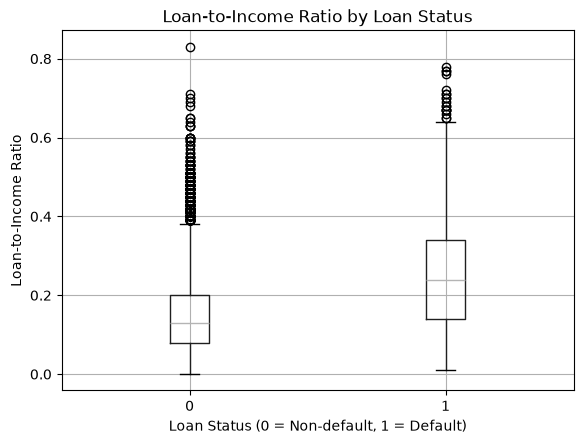

In [127]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_percent_income",
    by="loan_status"
)

plt.title("Loan-to-Income Ratio by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Loan-to-Income Ratio")

plt.show()

<Figure size 800x500 with 0 Axes>

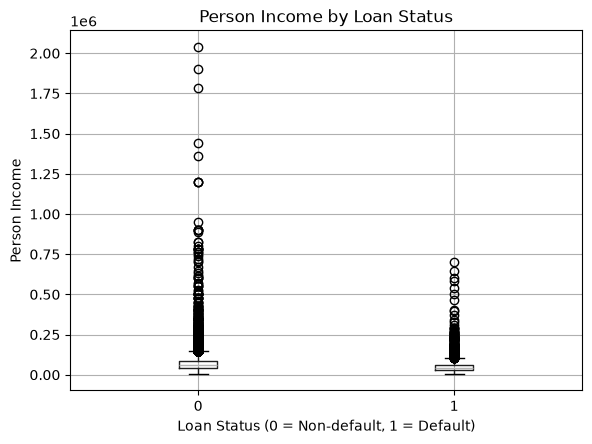

In [128]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="person_income",
    by="loan_status"
)

plt.title("Person Income by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Person Income")

plt.show()

<Figure size 800x500 with 0 Axes>

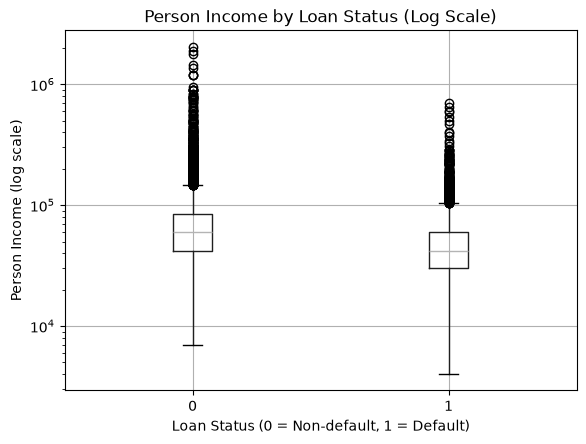

In [129]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="person_income",
    by="loan_status"
)

plt.yscale("log")
plt.title("Person Income by Loan Status (Log Scale)")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Person Income (log scale)")

plt.show()

<Figure size 800x500 with 0 Axes>

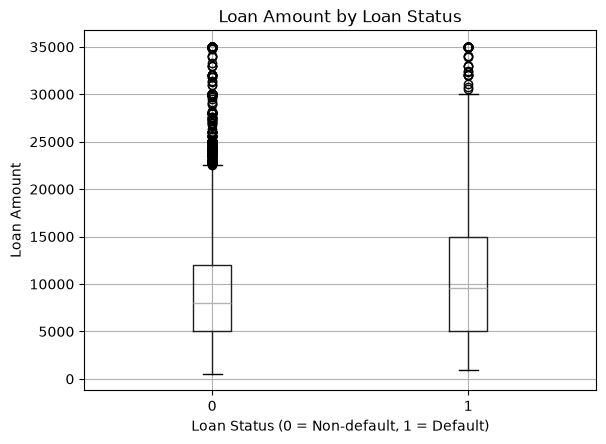

In [130]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_amnt",
    by="loan_status"
)

plt.title("Loan Amount by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Loan Amount")

plt.show()

<Figure size 800x500 with 0 Axes>

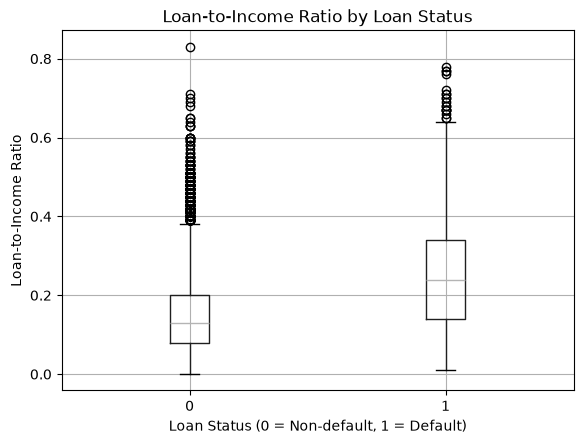

In [131]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_percent_income",
    by="loan_status"
)

plt.title("Loan-to-Income Ratio by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Loan-to-Income Ratio")

plt.show()

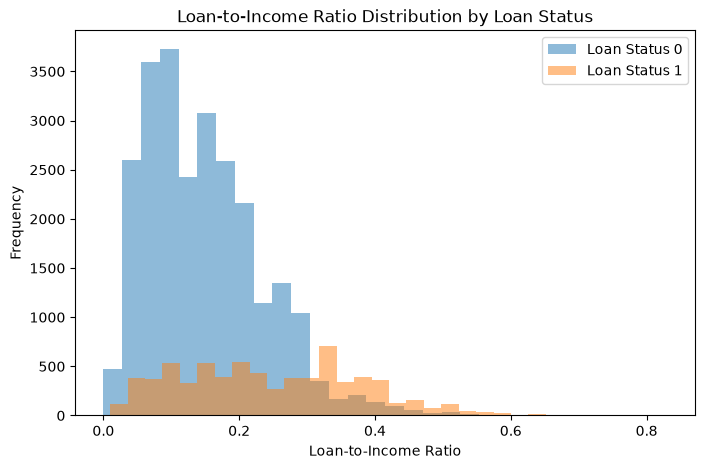

In [132]:
plt.figure(figsize=(8, 5))

for status in [0, 1]:
    data = df_clean.loc[
        df_clean["loan_status"] == status,
        "loan_percent_income"
    ]
    
    plt.hist(
        data,
        bins=30,
        alpha=0.5,
        label=f"Loan Status {status}"
    )

plt.title("Loan-to-Income Ratio Distribution by Loan Status")
plt.xlabel("Loan-to-Income Ratio")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [133]:
interest_rate_by_status = (
    df_clean.groupby("loan_status")["loan_int_rate"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

interest_rate_by_status

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,10.65,10.451972,2.956617,5.42,22.06
1,7088,13.48,13.049254,3.273892,5.42,23.22


<Figure size 800x500 with 0 Axes>

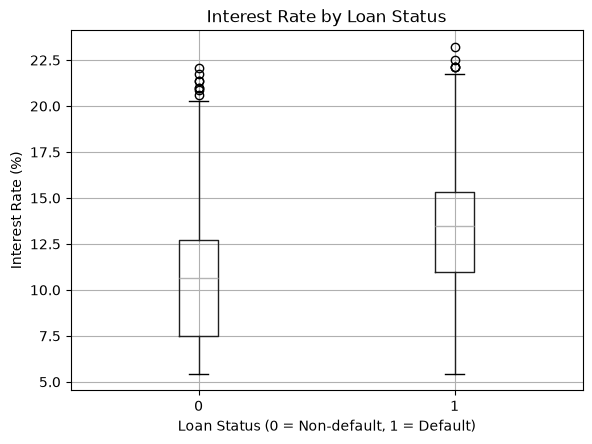

In [134]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_int_rate",
    by="loan_status"
)

plt.title("Interest Rate by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Interest Rate (%)")

plt.show()

In [135]:
pd.crosstab(
    pd.cut(
        df_clean["loan_int_rate"],
        bins=[0, 8, 10, 12, 14, 16, 18, 20, 25],
        include_lowest=True
    ),
    df_clean["loan_status"],
    normalize="index"
) * 100

loan_status,0,1
loan_int_rate,,
"(-0.001, 8.0]",90.635188,9.364812
"(8.0, 10.0]",85.706595,14.293405
"(10.0, 12.0]",83.304940,16.695060
"(12.0, 14.0]",78.819725,21.180275
"(14.0, 16.0]",52.379790,47.620210
"(16.0, 18.0]",39.005602,60.994398
"(18.0, 20.0]",34.036939,65.963061
"(20.0, 25.0]",13.924051,86.075949


In [136]:
emp_length_by_status = (
    df_clean.groupby("loan_status")["person_emp_length"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

emp_length_by_status

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,4.0,4.942538,4.017691,0.0,41.0
1,7088,3.0,4.114137,3.790378,0.0,34.0


In [137]:
pd.crosstab(
    df_clean["person_emp_length"],
    df_clean["loan_status"],
    normalize="index"
).mul(100).round(2)

loan_status,0,1
person_emp_length,,
0.0,72.03,27.97
1.0,72.28,27.72
2.0,74.24,25.76
3.0,79.82,20.18
4.0,76.27,23.73
5.0,81.27,18.73
6.0,81.22,18.78
7.0,81.19,18.81
8.0,83.29,16.71


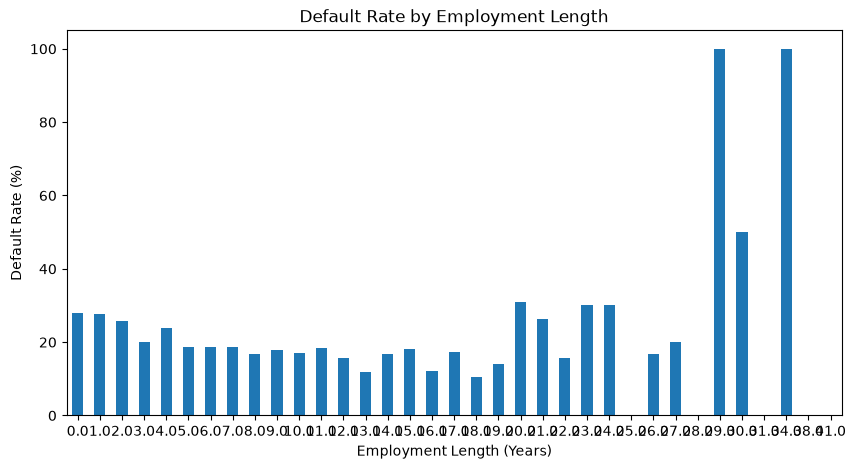

In [138]:
plt.figure(figsize=(10, 5))

default_rate_emp = (
    df_clean.groupby("person_emp_length")["loan_status"]
    .mean()
    .mul(100)
)

default_rate_emp.plot(kind="bar")

plt.title("Default Rate by Employment Length")
plt.xlabel("Employment Length (Years)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [139]:
df_clean["emp_group"] = pd.cut(
    df_clean["person_emp_length"],
    bins=[-1, 2, 5, 10, 15, 20, 50],
    labels=[
        "0-2 years",
        "3-5 years",
        "6-10 years",
        "11-15 years",
        "16-20 years",
        "21+ years"
    ]
)

In [140]:
emp_group_analysis = (
    df_clean.groupby("emp_group", observed=True)["loan_status"]
    .agg(["count", "sum", "mean"])
)

emp_group_analysis["default_rate_%"] = (
    emp_group_analysis["mean"] * 100
).round(2)

emp_group_analysis

,count,sum,mean,default_rate_%
emp_group,,,,
0-2 years,10814,2933,0.271222,27.12
3-5 years,10116,2132,0.210755,21.08
6-10 years,8564,1550,0.180990,18.10
11-15 years,2303,374,0.162397,16.24
16-20 years,503,75,0.149105,14.91
21+ years,109,24,0.220183,22.02


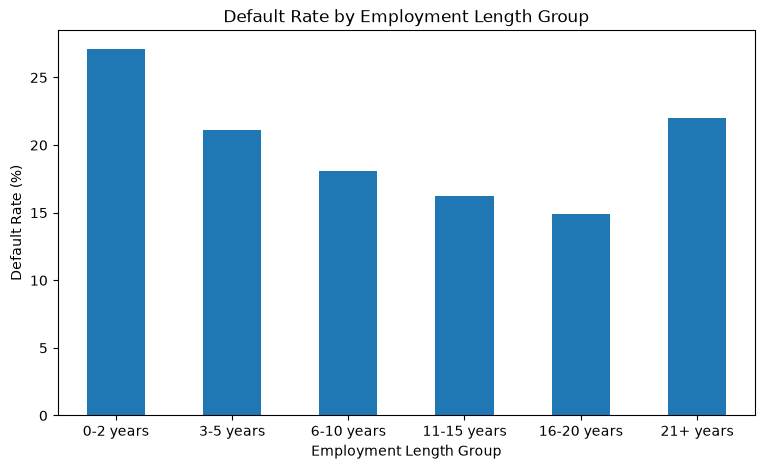

In [141]:
plt.figure(figsize=(9, 5))

emp_group_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Employment Length Group")
plt.xlabel("Employment Length Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [142]:
df_clean["person_home_ownership"].value_counts()

person_home_ownership
RENT        16374
MORTGAGE    13366
OWN          2563
OTHER         106
Name: count, dtype: int64

In [143]:
home_ownership_analysis = (
    df_clean.groupby("person_home_ownership")["loan_status"]
    .agg(["count", "sum", "mean"])
)

home_ownership_analysis["default_rate_%"] = (
    home_ownership_analysis["mean"] * 100
).round(2)

home_ownership_analysis

,count,sum,mean,default_rate_%
person_home_ownership,,,,
MORTGAGE,13366,1687,0.126216,12.62
OTHER,106,33,0.311321,31.13
OWN,2563,192,0.074912,7.49
RENT,16374,5176,0.316111,31.61


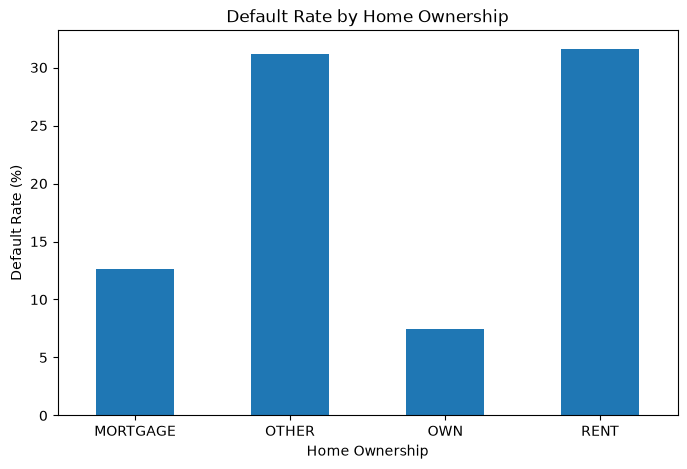

In [144]:
plt.figure(figsize=(8, 5))

home_ownership_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [145]:
# Default rate by loan intent

intent_analysis = (
    df_clean.groupby("loan_intent")["loan_status"]
    .agg(["count", "sum", "mean"])
)

intent_analysis["default_rate_%"] = (
    intent_analysis["mean"] * 100
).round(2)

intent_analysis = intent_analysis.sort_values(
    "default_rate_%",
    ascending=False
)

intent_analysis

,count,sum,mean,default_rate_%
loan_intent,,,,
DEBTCONSOLIDATION,5189,1488,0.286760,28.68
MEDICAL,6042,1617,0.267627,26.76
HOMEIMPROVEMENT,3594,940,0.261547,26.15
PERSONAL,5496,1093,0.198872,19.89
EDUCATION,6409,1106,0.172570,17.26
VENTURE,5679,844,0.148618,14.86


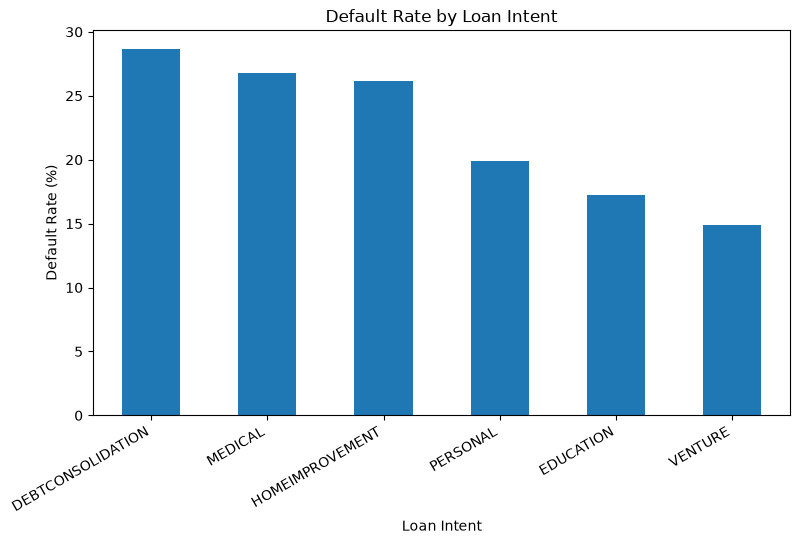

In [146]:
plt.figure(figsize=(9, 5))

intent_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30, ha="right")

plt.show()

In [147]:
pd.crosstab(
    df_clean["loan_intent"],
    df_clean["loan_status"],
    normalize="index"
).mul(100).round(2)

loan_status,0,1
loan_intent,,
DEBTCONSOLIDATION,71.32,28.68
EDUCATION,82.74,17.26
HOMEIMPROVEMENT,73.85,26.15
MEDICAL,73.24,26.76
PERSONAL,80.11,19.89
VENTURE,85.14,14.86


In [148]:
intent_analysis[["count", "sum", "default_rate_%"]]

,count,sum,default_rate_%
loan_intent,,,
DEBTCONSOLIDATION,5189,1488,28.68
MEDICAL,6042,1617,26.76
HOMEIMPROVEMENT,3594,940,26.15
PERSONAL,5496,1093,19.89
EDUCATION,6409,1106,17.26
VENTURE,5679,844,14.86


In [149]:
print("Credit Bureau Default History Distribution:")

print(
    df_clean["cb_person_default_on_file"]
    .value_counts()
)

print("\nCredit Bureau Default History Percentage:")

print(
    df_clean["cb_person_default_on_file"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Credit Bureau Default History Distribution:
cb_person_default_on_file
N    26680
Y     5729
Name: count, dtype: int64

Credit Bureau Default History Percentage:
cb_person_default_on_file
N    82.32
Y    17.68
Name: proportion, dtype: float64


In [150]:
cb_default_analysis = (
    df_clean.groupby("cb_person_default_on_file")["loan_status"]
    .agg(["count", "sum", "mean"])
)

cb_default_analysis["default_rate_%"] = (
    cb_default_analysis["mean"] * 100
).round(2)

cb_default_analysis = cb_default_analysis.sort_values(
    "default_rate_%",
    ascending=False
)

cb_default_analysis

,count,sum,mean,default_rate_%
cb_person_default_on_file,,,,
Y,5729,2169,0.37860,37.86
N,26680,4919,0.18437,18.44


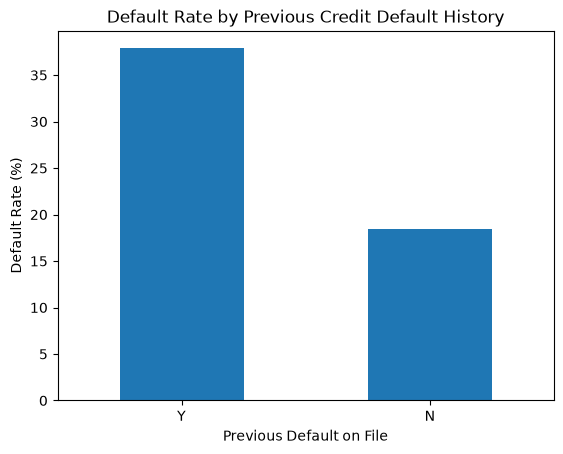

In [151]:
cb_default_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Previous Credit Default History")
plt.xlabel("Previous Default on File")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [152]:
pd.crosstab(
    df_clean["cb_person_default_on_file"],
    df_clean["loan_status"],
    normalize="index"
).mul(100).round(2)

loan_status,0,1
cb_person_default_on_file,,
N,81.56,18.44
Y,62.14,37.86


In [153]:
numeric_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "loan_status"
]

corr_matrix = df_clean[numeric_cols].corr()

corr_matrix.round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
person_age,1.00,0.14,0.17,0.05,0.01,-0.04,0.88,-0.02
person_income,0.14,1.00,0.16,0.32,-0.01,-0.29,0.12,-0.17
person_emp_length,0.17,0.16,1.00,0.11,-0.05,-0.06,0.15,-0.09
loan_amnt,0.05,0.32,0.11,1.00,0.14,0.57,0.04,0.11
loan_int_rate,0.01,-0.01,-0.05,0.14,1.00,0.12,0.02,0.33
loan_percent_income,-0.04,-0.29,-0.06,0.57,0.12,1.00,-0.03,0.38
cb_person_cred_hist_length,0.88,0.12,0.15,0.04,0.02,-0.03,1.00,-0.02
loan_status,-0.02,-0.17,-0.09,0.11,0.33,0.38,-0.02,1.00


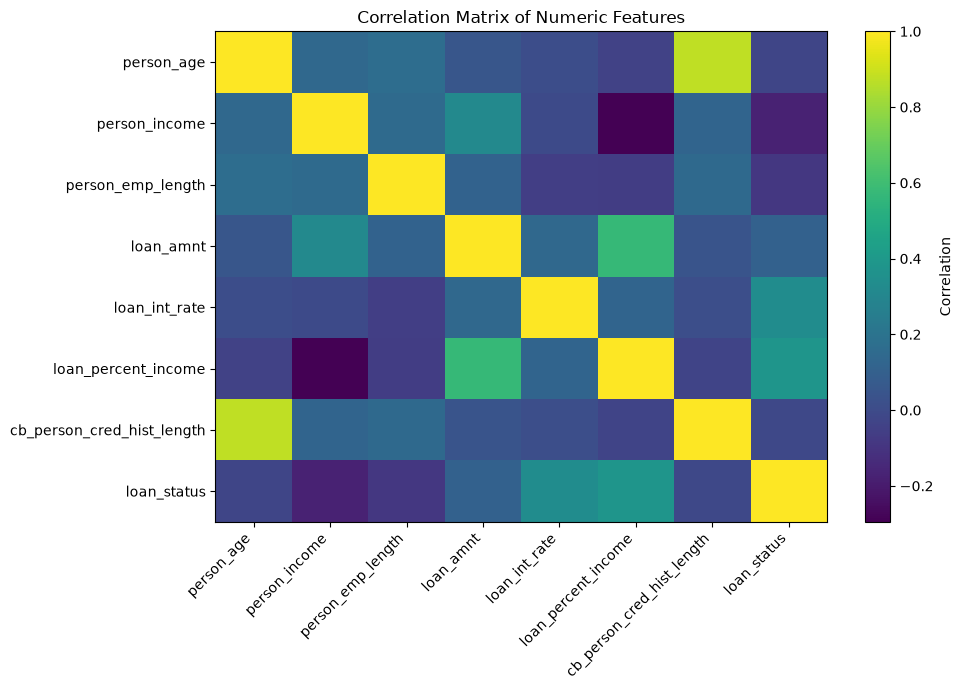

In [154]:
plt.figure(figsize=(10, 7))

plt.imshow(corr_matrix, aspect="auto")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.colorbar(label="Correlation")

plt.title("Correlation Matrix of Numeric Features")

plt.tight_layout()
plt.show()

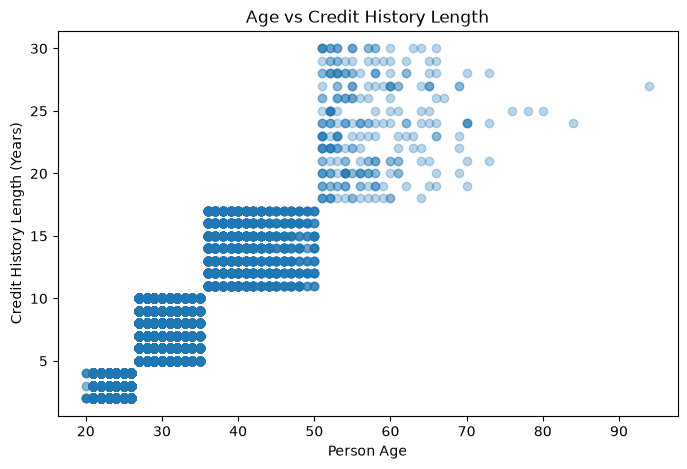

In [155]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["person_age"],
    df_clean["cb_person_cred_hist_length"],
    alpha=0.3
)

plt.title("Age vs Credit History Length")
plt.xlabel("Person Age")
plt.ylabel("Credit History Length (Years)")

plt.show()

In [156]:
df_clean[
    ["person_age", "cb_person_cred_hist_length"]
].describe()

,person_age,cb_person_cred_hist_length
count,32409.000000,32409.000000
mean,27.730754,5.811194
std,6.210445,4.057899
min,20.000000,2.000000
25%,23.000000,3.000000
50%,26.000000,4.000000
75%,30.000000,8.000000
max,94.000000,30.000000


In [157]:
df_clean[
    ["person_age", "cb_person_cred_hist_length"]
].corr().round(2)

,person_age,cb_person_cred_hist_length
person_age,1.00,0.88
cb_person_cred_hist_length,0.88,1.00


In [158]:
# Default rate by age group

df_clean["age_group_eda"] = pd.cut(
    df_clean["person_age"],
    bins=[0, 22, 25, 30, 35, 40, 50, 60, 100],
    labels=[
        "≤22",
        "23-25",
        "26-30",
        "31-35",
        "36-40",
        "41-50",
        "51-60",
        "61+"
    ]
)

age_default_analysis = (
    df_clean.groupby("age_group_eda", observed=True)["loan_status"]
    .agg(["count", "sum", "mean"])
)

age_default_analysis["default_rate_%"] = (
    age_default_analysis["mean"] * 100
).round(2)

age_default_analysis

,count,sum,mean,default_rate_%
age_group_eda,,,,
≤22,4833,1253,0.259259,25.93
23-25,10410,2273,0.218348,21.83
26-30,9429,1971,0.209036,20.90
31-35,4282,866,0.202242,20.22
36-40,1969,407,0.206704,20.67
41-50,1203,245,0.203658,20.37
51-60,218,56,0.256881,25.69
61+,65,17,0.261538,26.15


In [159]:
credit_hist_default = (
    df_clean.groupby("loan_status")["cb_person_cred_hist_length"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

credit_hist_default

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,4.0,5.846491,4.043993,2,30
1,7088,4.0,5.685102,4.104999,2,30


<Figure size 800x500 with 0 Axes>

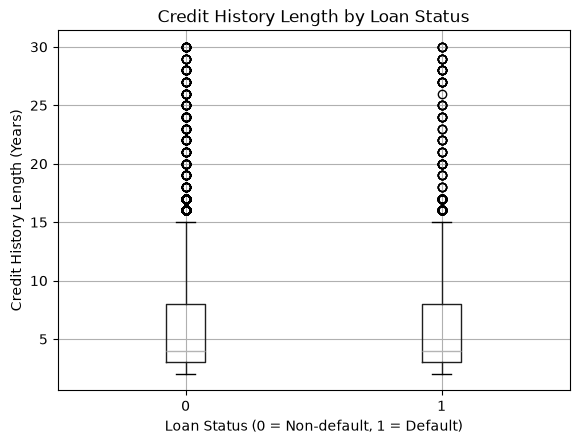

In [160]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="cb_person_cred_hist_length",
    by="loan_status"
)

plt.title("Credit History Length by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Credit History Length (Years)")

plt.show()

In [161]:
age_default_analysis = (
    df_clean.groupby("age_group_eda", observed=True)["loan_status"]
    .agg(["count", "sum", "mean"])
)

age_default_analysis["default_rate_%"] = (
    age_default_analysis["mean"] * 100
).round(2)

age_default_analysis

,count,sum,mean,default_rate_%
age_group_eda,,,,
≤22,4833,1253,0.259259,25.93
23-25,10410,2273,0.218348,21.83
26-30,9429,1971,0.209036,20.90
31-35,4282,866,0.202242,20.22
36-40,1969,407,0.206704,20.67
41-50,1203,245,0.203658,20.37
51-60,218,56,0.256881,25.69
61+,65,17,0.261538,26.15


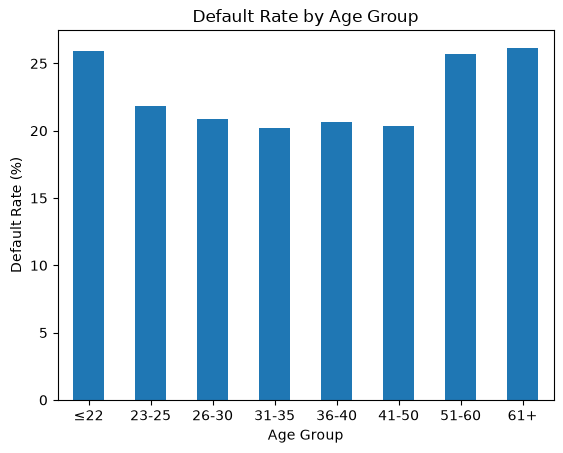

In [162]:
age_default_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [163]:
loan_pct_income_analysis = (
    df_clean.groupby(
        pd.cut(
            df_clean["loan_percent_income"],
            bins=[0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 1.0],
            include_lowest=True
        ),
        observed=True
    )["loan_status"]
    .agg(["count", "sum", "mean"])
)

loan_pct_income_analysis["default_rate_%"] = (
    loan_pct_income_analysis["mean"] * 100
).round(2)

loan_pct_income_analysis

,count,sum,mean,default_rate_%
loan_percent_income,,,,
"(-0.001, 0.05]",3429,352,0.102654,10.27
"(0.05, 0.1]",6997,874,0.124911,12.49
"(0.1, 0.15]",6660,855,0.128378,12.84
"(0.15, 0.2]",5339,960,0.179809,17.98
"(0.2, 0.25]",3736,732,0.195931,19.59
"(0.25, 0.3]",2430,626,0.257613,25.76
"(0.3, 0.4]",2700,1860,0.688889,68.89
"(0.4, 1.0]",1118,829,0.741503,74.15


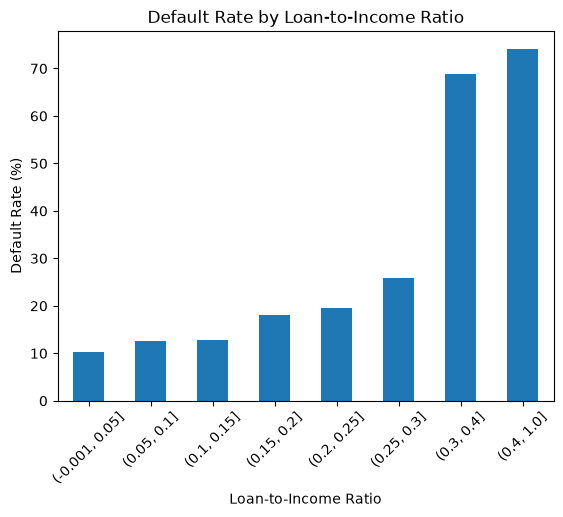

In [164]:
loan_pct_income_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Loan-to-Income Ratio")
plt.xlabel("Loan-to-Income Ratio")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [165]:
# Create temporary Loan-to-Income ratio groups
df_clean["loan_pct_income_group"] = pd.cut(
    df_clean["loan_percent_income"],
    bins=[0, 0.10, 0.20, 0.30, 0.40, 1.0],
    include_lowest=True
)

loan_pct_amount_analysis = (
    df_clean.groupby(
        "loan_pct_income_group",
        observed=True
    )["loan_amnt"]
    .agg(["count", "median", "mean", "min", "max"])
)

loan_pct_amount_analysis.round(2)

,count,median,mean,min,max
loan_pct_income_group,,,,,
"(-0.001, 0.1]",10426,4500.0,5253.87,500,35000
"(0.1, 0.2]",11999,8500.0,9649.70,1000,35000
"(0.2, 0.3]",6166,12000.0,12982.39,1200,35000
"(0.3, 0.4]",2700,14400.0,15140.83,1400,35000
"(0.4, 1.0]",1118,16000.0,17343.11,2000,35000


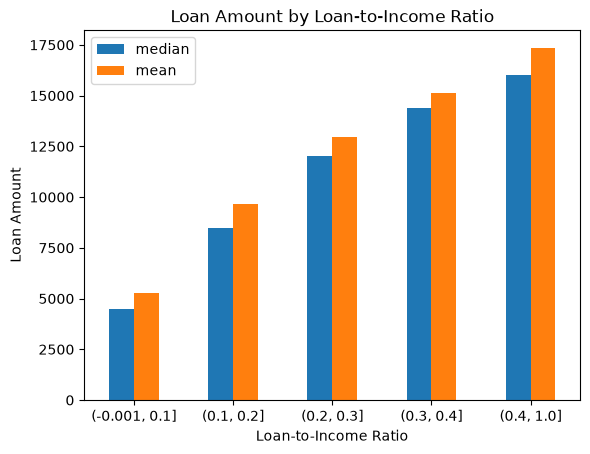

In [166]:
loan_pct_amount_analysis[["median", "mean"]].plot(kind="bar")

plt.title("Loan Amount by Loan-to-Income Ratio")
plt.xlabel("Loan-to-Income Ratio")
plt.ylabel("Loan Amount")
plt.xticks(rotation=0)

plt.show()

In [167]:
income_default_analysis = (
    df_clean.groupby("loan_status")["person_income"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

income_default_analysis.round(2)

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,60000.0,70597.36,55311.48,7000,2039784
1,7088,41655.0,49093.10,36344.73,4000,703800


<Figure size 800x500 with 0 Axes>

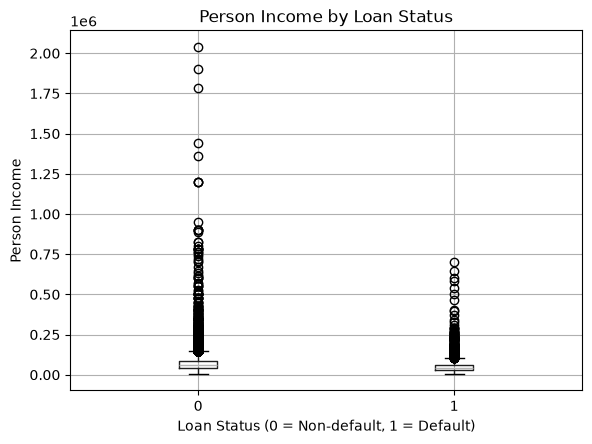

In [168]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="person_income",
    by="loan_status"
)

plt.title("Person Income by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Person Income")

plt.show()

<Figure size 800x500 with 0 Axes>

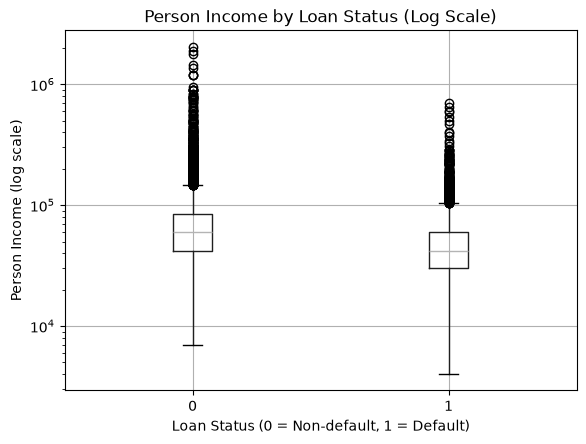

In [169]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="person_income",
    by="loan_status"
)

plt.yscale("log")

plt.title("Person Income by Loan Status (Log Scale)")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Person Income (log scale)")

plt.show()

In [170]:
df_clean["person_income_log"] = np.log1p(df_clean["person_income"])

In [171]:
loan_amount_default = (
    df_clean.groupby("loan_status")["loan_amnt"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

loan_amount_default.round(2)

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,8000.0,9239.34,6025.32,500,35000
1,7088,9600.0,10854.07,7138.58,900,35000


<Figure size 800x500 with 0 Axes>

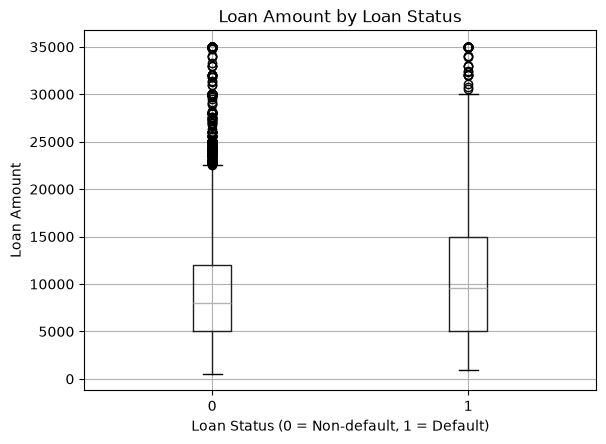

In [172]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_amnt",
    by="loan_status"
)

plt.title("Loan Amount by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Loan Amount")

plt.show()

<Figure size 800x500 with 0 Axes>

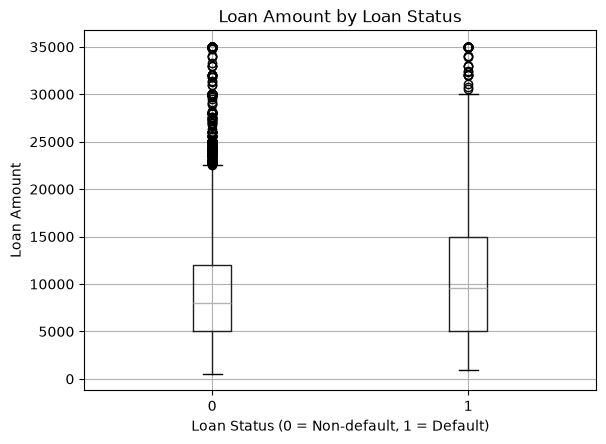

In [173]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_amnt",
    by="loan_status"
)

plt.title("Loan Amount by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Loan Amount")

plt.show()

In [174]:
interest_rate_default = (
    df_clean.groupby("loan_status")["loan_int_rate"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

interest_rate_default.round(2)

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,10.65,10.45,2.96,5.42,22.06
1,7088,13.48,13.05,3.27,5.42,23.22


<Figure size 800x500 with 0 Axes>

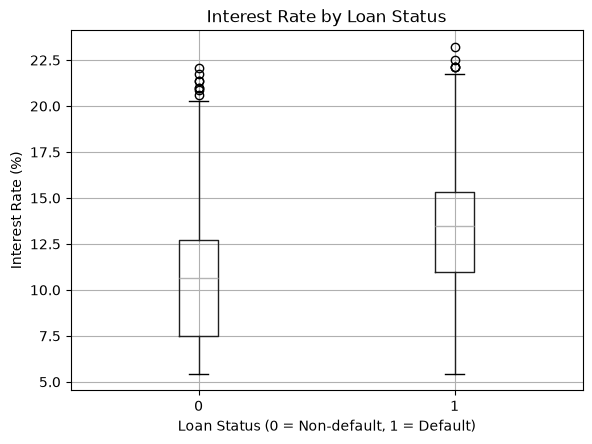

In [175]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_int_rate",
    by="loan_status"
)

plt.title("Interest Rate by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Interest Rate (%)")

plt.show()

In [176]:
interest_rate_analysis = (
    df_clean.groupby(
        pd.cut(
            df_clean["loan_int_rate"],
            bins=[0, 8, 10, 12, 14, 16, 18, 20, 25],
            include_lowest=True
        ),
        observed=True
    )["loan_status"]
    .agg(["count", "sum", "mean"])
)

interest_rate_analysis["default_rate_%"] = (
    interest_rate_analysis["mean"] * 100
).round(2)

interest_rate_analysis

,count,sum,mean,default_rate_%
loan_int_rate,,,,
"(-0.001, 8.0]",8895,833,0.093648,9.36
"(8.0, 10.0]",3715,531,0.142934,14.29
"(10.0, 12.0]",7631,1274,0.166951,16.70
"(12.0, 14.0]",6185,1310,0.211803,21.18
"(14.0, 16.0]",4097,1951,0.476202,47.62
"(16.0, 18.0]",1428,871,0.609944,60.99
"(18.0, 20.0]",379,250,0.659631,65.96
"(20.0, 25.0]",79,68,0.860759,86.08


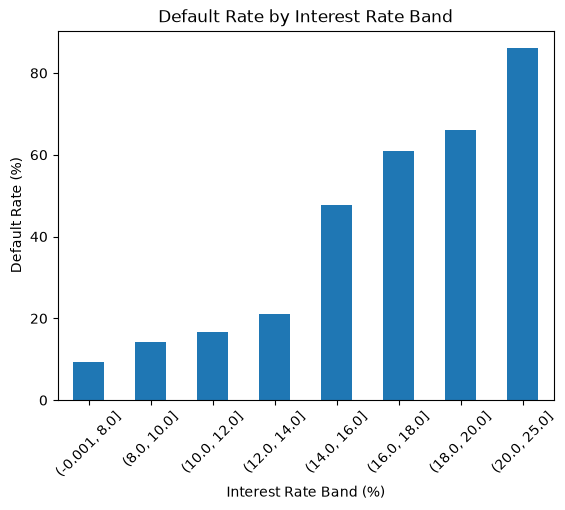

In [177]:
interest_rate_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Interest Rate Band")
plt.xlabel("Interest Rate Band (%)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [178]:
loan_pct_income_default = (
    df_clean.groupby("loan_status")["loan_percent_income"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

loan_pct_income_default.round(3)

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,0.13,0.149,0.087,0.00,0.83
1,7088,0.24,0.247,0.132,0.01,0.78


<Figure size 800x500 with 0 Axes>

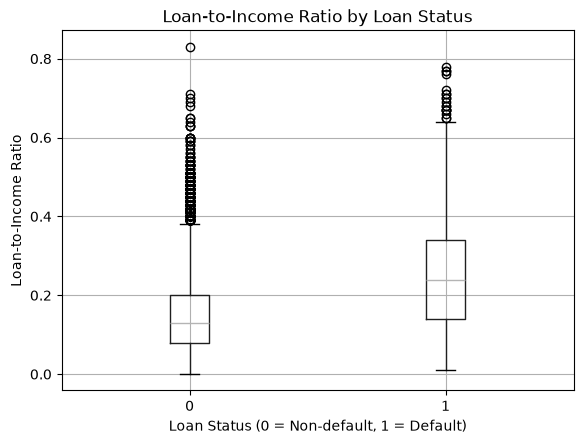

In [179]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="loan_percent_income",
    by="loan_status"
)

plt.title("Loan-to-Income Ratio by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Loan-to-Income Ratio")

plt.show()

In [180]:
credit_hist_default = (
    df_clean.groupby("loan_status")["cb_person_cred_hist_length"]
    .agg(["count", "median", "mean", "std", "min", "max"])
)

credit_hist_default.round(2)

,count,median,mean,std,min,max
loan_status,,,,,,
0,25321,4.0,5.85,4.04,2,30
1,7088,4.0,5.69,4.10,2,30


In [181]:
df_clean["credit_hist_group"] = pd.cut(
    df_clean["cb_person_cred_hist_length"],
    bins=[0, 3, 5, 10, 15, 20, 30],
    labels=[
        "0-3 years",
        "4-5 years",
        "6-10 years",
        "11-15 years",
        "16-20 years",
        "21+ years"
    ],
    include_lowest=True
)

In [182]:
credit_hist_analysis = (
    df_clean.groupby("credit_hist_group", observed=True)["loan_status"]
    .agg(["count", "sum", "mean"])
)

credit_hist_analysis["default_rate_%"] = (
    credit_hist_analysis["mean"] * 100
).round(2)

credit_hist_analysis

,count,sum,mean,default_rate_%
credit_hist_group,,,,
0-3 years,11826,2724,0.230340,23.03
4-5 years,7754,1703,0.219629,21.96
6-10 years,9374,1936,0.206529,20.65
11-15 years,2317,478,0.206301,20.63
16-20 years,926,192,0.207343,20.73
21+ years,212,55,0.259434,25.94


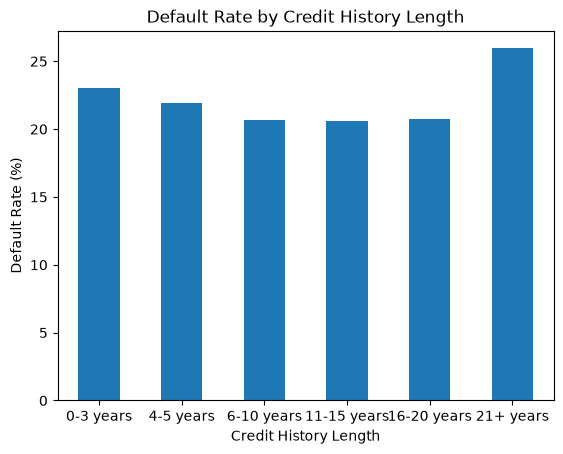

In [183]:
credit_hist_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Credit History Length")
plt.xlabel("Credit History Length")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

<Figure size 800x500 with 0 Axes>

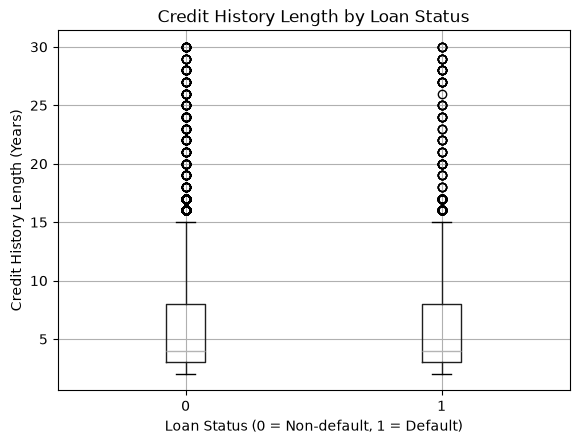

In [184]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="cb_person_cred_hist_length",
    by="loan_status"
)

plt.title("Credit History Length by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Credit History Length (Years)")

plt.show()

In [185]:
loan_amount_analysis = (
    df_clean.groupby(
        pd.cut(
            df_clean["loan_amnt"],
            bins=[0, 5000, 10000, 15000, 20000, 25000, 30000, 35000],
            include_lowest=True
        ),
        observed=True
    )["loan_status"]
    .agg(["count", "sum", "mean"])
)

loan_amount_analysis["default_rate_%"] = (
    loan_amount_analysis["mean"] * 100
).round(2)

loan_amount_analysis

,count,sum,mean,default_rate_%
loan_amnt,,,,
"(-0.001, 5000.0]",9428,1930,0.204709,20.47
"(5000.0, 10000.0]",11982,2162,0.180437,18.04
"(10000.0, 15000.0]",6091,1406,0.230832,23.08
"(15000.0, 20000.0]",2781,848,0.304926,30.49
"(20000.0, 25000.0]",1678,592,0.352801,35.28
"(25000.0, 30000.0]",231,76,0.329004,32.90
"(30000.0, 35000.0]",218,74,0.339450,33.94


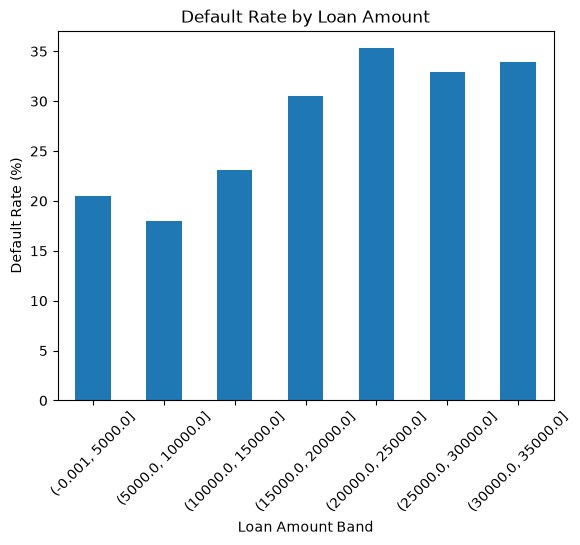

In [186]:
loan_amount_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Loan Amount")
plt.xlabel("Loan Amount Band")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [187]:
df_clean["person_income_log"] = np.log1p(df_clean["person_income"])

In [188]:
income_default_analysis = (
    df_clean.groupby(
        pd.cut(
            df_clean["person_income"],
            bins=[0, 30000, 50000, 75000, 100000, 150000, 250000, 500000, 2500000],
            include_lowest=True
        ),
        observed=True
    )["loan_status"]
    .agg(["count", "sum", "mean"])
)

income_default_analysis["default_rate_%"] = (
    income_default_analysis["mean"] * 100
).round(2)

income_default_analysis

,count,sum,mean,default_rate_%
person_income,,,,
"(-0.001, 30000.0]",4486,2045,0.455863,45.59
"(30000.0, 50000.0]",9513,2441,0.256596,25.66
"(50000.0, 75000.0]",9584,1690,0.176336,17.63
"(75000.0, 100000.0]",4639,512,0.110369,11.04
"(100000.0, 150000.0]",3059,289,0.094475,9.45
"(150000.0, 250000.0]",897,85,0.094760,9.48
"(250000.0, 500000.0]",180,21,0.116667,11.67
"(500000.0, 2500000.0]",51,5,0.098039,9.80


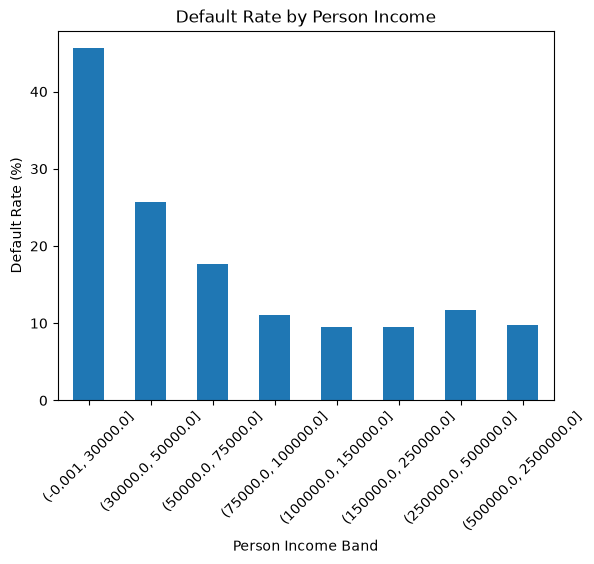

In [189]:
income_default_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Person Income")
plt.xlabel("Person Income Band")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [190]:
df_clean["person_income_log"] = np.log1p(df_clean["person_income"])

In [191]:
categorical_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns

categorical_cols

C:\Users\sumit\AppData\Local\Temp\ipykernel_2200\158594110.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(


Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file', 'age_group', 'emp_group', 'age_group_eda',
       'loan_pct_income_group', 'credit_hist_group'],
      dtype='str')

In [192]:
original_categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

original_categorical_cols

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

In [193]:
loan_grade_analysis = (
    df_clean.groupby("loan_grade")["loan_status"]
    .agg(["count", "sum", "mean"])
)

loan_grade_analysis["default_rate_%"] = (
    loan_grade_analysis["mean"] * 100
).round(2)

loan_grade_analysis

,count,sum,mean,default_rate_%
loan_grade,,,,
A,10702,1066,0.099608,9.96
B,10384,1695,0.163232,16.32
C,6436,1336,0.207582,20.76
D,3619,2137,0.590495,59.05
E,963,621,0.644860,64.49
F,241,170,0.705394,70.54
G,64,63,0.984375,98.44


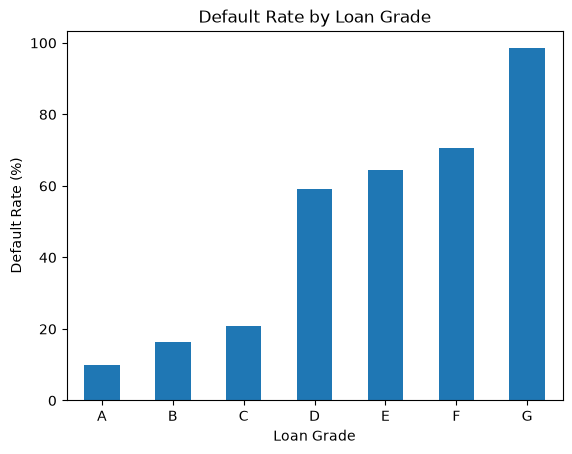

In [194]:
loan_grade_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [195]:
# Final missing-value check

missing_summary = (
    df_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_summary[missing_summary > 0]

Series([], dtype: int64)

In [196]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [197]:
print("Number of duplicate rows:", df_clean.duplicated().sum())

Number of duplicate rows: 0


In [198]:
print("Number of columns:", len(df_clean.columns))

for col in df_clean.columns:
    print(col)

Number of columns: 18
person_age
person_income
person_home_ownership
person_emp_length
loan_intent
loan_grade
loan_amnt
loan_int_rate
loan_status
loan_percent_income
cb_person_default_on_file
cb_person_cred_hist_length
age_group
emp_group
age_group_eda
loan_pct_income_group
person_income_log
credit_hist_group


In [199]:
df_clean.dtypes

person_age                       int64
person_income                    int64
person_home_ownership              str
person_emp_length              float64
loan_intent                        str
loan_grade                         str
loan_amnt                        int64
loan_int_rate                  float64
loan_status                      int64
loan_percent_income            float64
cb_person_default_on_file          str
cb_person_cred_hist_length       int64
age_group                     category
emp_group                     category
age_group_eda                 category
loan_pct_income_group         category
person_income_log              float64
credit_hist_group             category
dtype: object

In [200]:
missing_summary = (
    df_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_summary[missing_summary > 0]

Series([], dtype: int64)

In [201]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [202]:
print("Number of duplicate rows:", df_clean.duplicated().sum())

Number of duplicate rows: 0


In [203]:
print("Number of columns:", len(df_clean.columns))

for col in df_clean.columns:
    print(col)

Number of columns: 18
person_age
person_income
person_home_ownership
person_emp_length
loan_intent
loan_grade
loan_amnt
loan_int_rate
loan_status
loan_percent_income
cb_person_default_on_file
cb_person_cred_hist_length
age_group
emp_group
age_group_eda
loan_pct_income_group
person_income_log
credit_hist_group


In [204]:
# Remove temporary EDA-only columns

eda_temp_cols = [
    "age_group",
    "emp_group",
    "age_group_eda",
    "loan_pct_income_group",
    "credit_hist_group"
]

df_model = df_clean.drop(columns=eda_temp_cols)

print("Shape:", df_model.shape)
print("\nColumns:")
print(df_model.columns.tolist())

Shape: (32409, 13)

Columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'person_income_log']


In [205]:
home_ownership_analysis = (
    df_clean.groupby("person_home_ownership")["loan_status"]
    .agg(["count", "sum", "mean"])
)

home_ownership_analysis["default_rate_%"] = (
    home_ownership_analysis["mean"] * 100
).round(2)

home_ownership_analysis

,count,sum,mean,default_rate_%
person_home_ownership,,,,
MORTGAGE,13366,1687,0.126216,12.62
OTHER,106,33,0.311321,31.13
OWN,2563,192,0.074912,7.49
RENT,16374,5176,0.316111,31.61


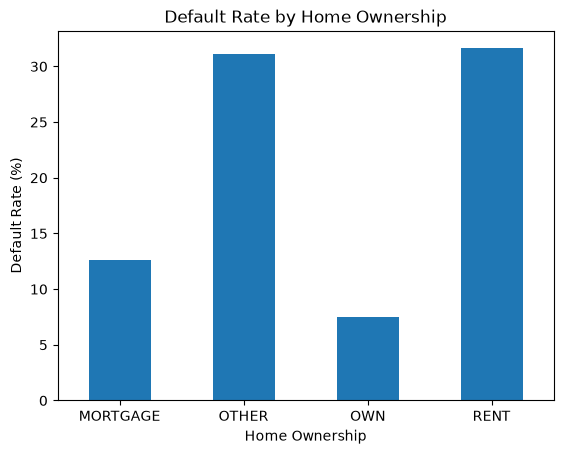

In [206]:
home_ownership_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [207]:
loan_intent_analysis = (
    df_clean.groupby("loan_intent")["loan_status"]
    .agg(["count", "sum", "mean"])
)

loan_intent_analysis["default_rate_%"] = (
    loan_intent_analysis["mean"] * 100
).round(2)

loan_intent_analysis

,count,sum,mean,default_rate_%
loan_intent,,,,
DEBTCONSOLIDATION,5189,1488,0.286760,28.68
EDUCATION,6409,1106,0.172570,17.26
HOMEIMPROVEMENT,3594,940,0.261547,26.15
MEDICAL,6042,1617,0.267627,26.76
PERSONAL,5496,1093,0.198872,19.89
VENTURE,5679,844,0.148618,14.86


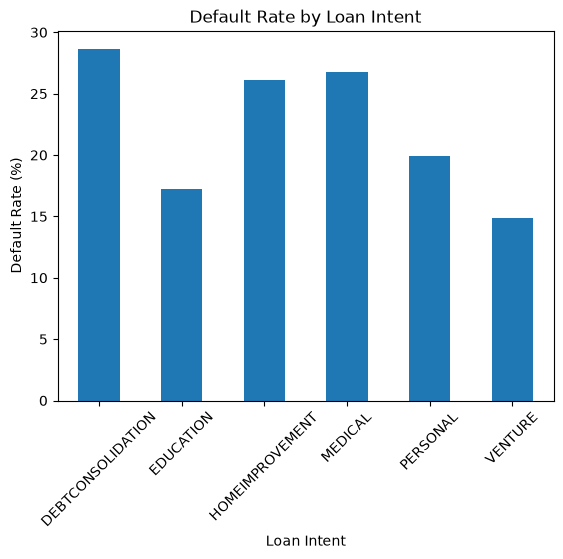

In [208]:
loan_intent_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [209]:
previous_default_analysis = (
    df_clean.groupby("cb_person_default_on_file")["loan_status"]
    .agg(["count", "sum", "mean"])
)

previous_default_analysis["default_rate_%"] = (
    previous_default_analysis["mean"] * 100
).round(2)

previous_default_analysis

,count,sum,mean,default_rate_%
cb_person_default_on_file,,,,
N,26680,4919,0.18437,18.44
Y,5729,2169,0.37860,37.86


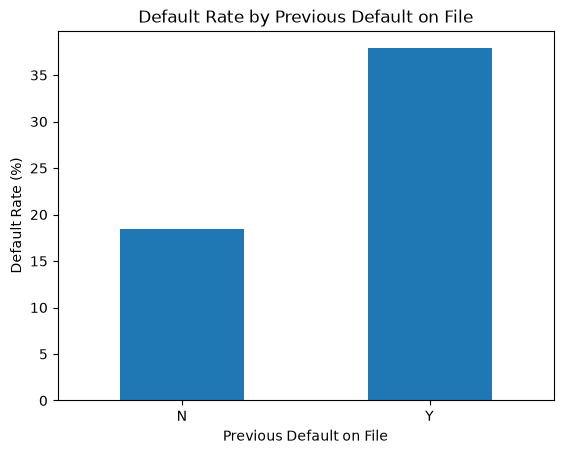

In [210]:
previous_default_analysis["default_rate_%"].plot(kind="bar")

plt.title("Default Rate by Previous Default on File")
plt.xlabel("Previous Default on File")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [211]:
grade_home_analysis = pd.crosstab(
    df_clean["loan_grade"],
    df_clean["person_home_ownership"],
    values=df_clean["loan_status"],
    aggfunc="mean"
).mul(100).round(2)

grade_home_analysis

person_home_ownership,MORTGAGE,OTHER,OWN,RENT
loan_grade,,,,
A,4.39,11.54,7.09,17.50
B,8.02,15.15,4.27,24.11
C,14.28,35.29,6.30,26.58
D,45.62,55.00,6.43,73.78
E,47.63,75.00,54.39,75.54
F,62.89,100.00,53.33,77.95
G,100.00,NaN,100.00,96.43


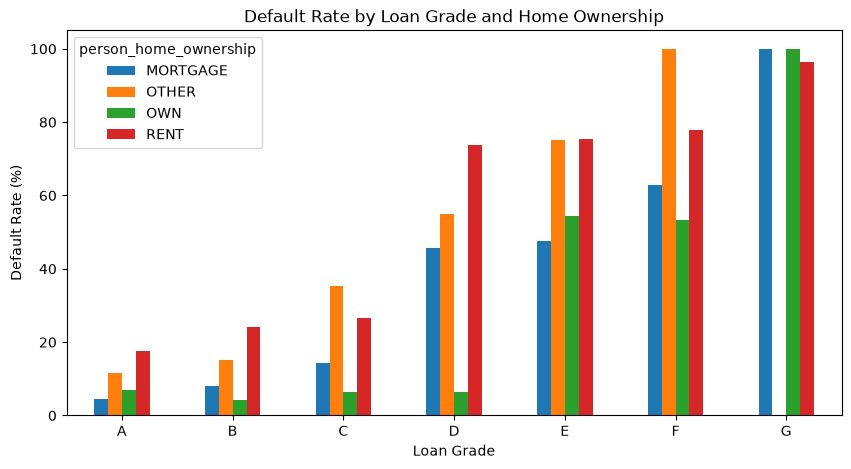

In [212]:
grade_home_analysis.plot(kind="bar", figsize=(10, 5))

plt.title("Default Rate by Loan Grade and Home Ownership")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [213]:
categorical_check = pd.crosstab(
    df_clean["loan_grade"],
    df_clean["person_home_ownership"],
    normalize="index"
).mul(100).round(2)

categorical_check

person_home_ownership,MORTGAGE,OTHER,OWN,RENT
loan_grade,,,,
A,50.62,0.24,8.57,40.57
B,38.76,0.32,7.68,53.25
C,34.93,0.26,7.64,57.16
D,33.43,0.55,7.74,58.28
E,35.10,0.83,5.92,58.15
F,40.25,0.83,6.22,52.70
G,48.44,0.00,7.81,43.75


In [214]:
grade_intent_check = pd.crosstab(
    df_clean["loan_grade"],
    df_clean["loan_intent"],
    normalize="index"
).mul(100).round(2)

grade_intent_check

loan_intent,DEBTCONSOLIDATION,EDUCATION,HOMEIMPROVEMENT,MEDICAL,PERSONAL,VENTURE
loan_grade,,,,,,
A,16.26,20.16,10.48,18.16,17.02,17.91
B,15.53,19.32,10.69,19.26,17.35,17.84
C,16.17,20.98,10.74,18.83,16.21,17.08
D,16.52,18.13,13.46,18.10,17.74,16.05
E,14.95,19.21,14.85,17.34,15.26,18.38
F,17.84,19.09,13.28,21.58,12.45,15.77
G,15.62,14.06,14.06,18.75,15.62,21.88


In [215]:
target_distribution = (
    df_model["loan_status"]
    .value_counts()
    .sort_index()
)

target_percentage = (
    df_model["loan_status"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Target Count:")
print(target_distribution)

print("\nTarget Percentage:")
print(target_percentage)

Target Count:
loan_status
0    25321
1     7088
Name: count, dtype: int64

Target Percentage:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


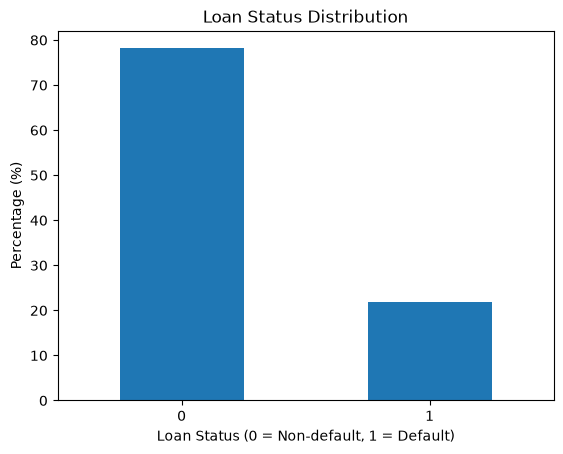

In [216]:
target_percentage.plot(kind="bar")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

In [217]:
print("Features:")
print(df_model.columns.tolist())

Features:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'person_income_log']


In [218]:
X = df_model.drop(columns="loan_status")
y = df_model["loan_status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

X shape: (32409, 12)
y shape: (32409,)

X columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'person_income_log']


In [219]:
# Numerical correlation with target

numeric_cols = df_model.select_dtypes(
    include=["int64", "float64"]
).columns

correlation_with_target = (
    df_model[numeric_cols]
    .corr()["loan_status"]
    .sort_values(ascending=False)
)

correlation_with_target

loan_status                   1.000000
loan_percent_income           0.379580
loan_int_rate                 0.334110
loan_amnt                     0.105601
cb_person_cred_hist_length   -0.016441
person_age                   -0.021774
person_emp_length            -0.085959
person_income                -0.169262
person_income_log            -0.283258
Name: loan_status, dtype: float64

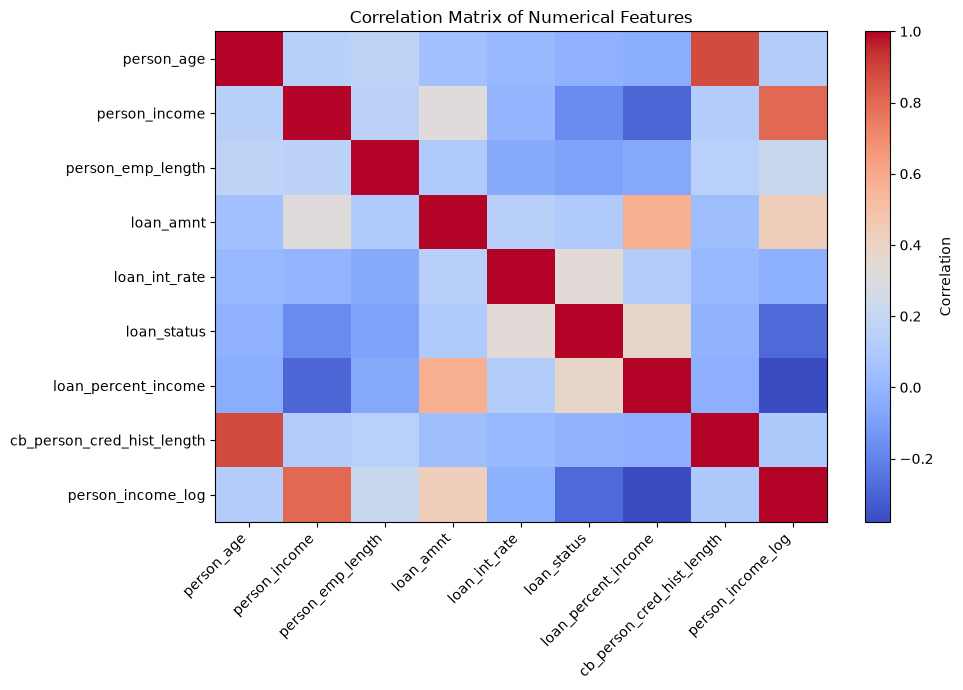

In [220]:
plt.figure(figsize=(10, 7))

corr_matrix = df_model[numeric_cols].corr()

plt.imshow(corr_matrix, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_cols)),
    numeric_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numeric_cols)),
    numeric_cols
)

plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

In [221]:
# Remove diagonal and duplicate correlations

corr_pairs = (
    corr_matrix
    .where(
        ~np.eye(corr_matrix.shape[0], dtype=bool)
    )
    .stack()
    .sort_values(ascending=False)
)

corr_pairs.head(15)

person_age                  cb_person_cred_hist_length    0.878240
cb_person_cred_hist_length  person_age                    0.878240
person_income               person_income_log             0.801048
person_income_log           person_income                 0.801048
loan_amnt                   loan_percent_income           0.572632
loan_percent_income         loan_amnt                     0.572632
person_income_log           loan_amnt                     0.426578
loan_amnt                   person_income_log             0.426578
loan_status                 loan_percent_income           0.379580
loan_percent_income         loan_status                   0.379580
loan_int_rate               loan_status                   0.334110
loan_status                 loan_int_rate                 0.334110
person_income               loan_amnt                     0.316732
loan_amnt                   person_income                 0.316732
person_emp_length           person_income_log             0.21

In [222]:
corr_pairs.tail(15)

person_income_log           loan_status                  -0.283258
loan_status                 person_income_log            -0.283258
person_income               loan_percent_income          -0.294766
loan_percent_income         person_income                -0.294766
                            person_income_log            -0.377459
person_income_log           loan_percent_income          -0.377459
person_age                  person_age                         NaN
person_income               person_income                      NaN
person_emp_length           person_emp_length                  NaN
loan_amnt                   loan_amnt                          NaN
loan_int_rate               loan_int_rate                      NaN
loan_status                 loan_status                        NaN
loan_percent_income         loan_percent_income                NaN
cb_person_cred_hist_length  cb_person_cred_hist_length         NaN
person_income_log           person_income_log                 

In [223]:
# Get only unique feature pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

corr_pairs_unique = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

corr_pairs_unique.head(15)

person_age         cb_person_cred_hist_length    0.878240
person_income      person_income_log             0.801048
loan_amnt          loan_percent_income           0.572632
                   person_income_log             0.426578
loan_status        loan_percent_income           0.379580
loan_int_rate      loan_status                   0.334110
person_income      loan_amnt                     0.316732
person_emp_length  person_income_log             0.215424
person_age         person_emp_length             0.170517
person_income      person_emp_length             0.155102
person_emp_length  cb_person_cred_hist_length    0.147871
loan_amnt          loan_int_rate                 0.142399
person_age         person_income                 0.140487
person_income      cb_person_cred_hist_length    0.122654
loan_int_rate      loan_percent_income           0.120515
dtype: float64

In [224]:
corr_pairs_unique.tail(15)

cb_person_cred_hist_length  person_emp_length            NaN
                            loan_amnt                    NaN
                            loan_int_rate                NaN
                            loan_status                  NaN
                            loan_percent_income          NaN
                            cb_person_cred_hist_length   NaN
person_income_log           person_age                   NaN
                            person_income                NaN
                            person_emp_length            NaN
                            loan_amnt                    NaN
                            loan_int_rate                NaN
                            loan_status                  NaN
                            loan_percent_income          NaN
                            cb_person_cred_hist_length   NaN
                            person_income_log            NaN
dtype: float64

In [225]:
# Get only unique feature pairs and remove NaN values

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

corr_pairs_unique = (
    upper_triangle
    .stack()
    .dropna()
    .sort_values(ascending=False)
)

print("Strongest positive correlations:")
print(corr_pairs_unique.head(15))

print("\nStrongest negative correlations:")
print(corr_pairs_unique.tail(15))

Strongest positive correlations:
person_age         cb_person_cred_hist_length    0.878240
person_income      person_income_log             0.801048
loan_amnt          loan_percent_income           0.572632
                   person_income_log             0.426578
loan_status        loan_percent_income           0.379580
loan_int_rate      loan_status                   0.334110
person_income      loan_amnt                     0.316732
person_emp_length  person_income_log             0.215424
person_age         person_emp_length             0.170517
person_income      person_emp_length             0.155102
person_emp_length  cb_person_cred_hist_length    0.147871
loan_amnt          loan_int_rate                 0.142399
person_age         person_income                 0.140487
person_income      cb_person_cred_hist_length    0.122654
loan_int_rate      loan_percent_income           0.120515
dtype: float64

Strongest negative correlations:
loan_int_rate        cb_person_cred_hist_length 

In [226]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns="loan_status")
y = df_model["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (25927, 12)
X_test : (6482, 12)
y_train: (25927,)
y_test : (6482,)


In [227]:
categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

In [228]:
# Identify numerical columns

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Numerical columns:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'person_income_log']


In [229]:
df_clean["person_income_log"] = np.log1p(df_clean["person_income"])

In [230]:
# Remove raw income because we already have its log-transformed version

X_train_model = X_train.drop(columns=["person_income"])
X_test_model = X_test.drop(columns=["person_income"])

print("X_train_model shape:", X_train_model.shape)
print("X_test_model shape:", X_test_model.shape)

X_train_model shape: (25927, 11)
X_test_model shape: (6482, 11)


In [231]:
print(X_train.columns.tolist())

['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'person_income_log']


In [232]:
categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

numerical_cols = X_train_model.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Numerical columns:
['person_age', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'person_income_log']


In [234]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_cols
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [235]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [236]:
# Train the Logistic Regression model

logistic_model.fit(X_train_model, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [237]:
# Make predictions on the test data

y_pred = logistic_model.predict(X_test_model)

# Probability of default (class 1)
y_pred_proba = logistic_model.predict_proba(X_test_model)[:, 1]

print("Predictions generated successfully.")
print("First 10 predictions:", y_pred[:10])
print("First 10 default probabilities:", y_pred_proba[:10])

Predictions generated successfully.
First 10 predictions: [0 0 0 0 1 0 1 0 0 0]
First 10 default probabilities: [0.11844275 0.19177631 0.364115   0.17434555 0.70398022 0.00638826
 0.69562641 0.11183879 0.02787409 0.08698589]


In [238]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("Baseline Logistic Regression Performance")
print("----------------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Baseline Logistic Regression Performance
----------------------------------------
Accuracy : 0.8661
Precision: 0.7589
Recall   : 0.5684
F1 Score : 0.65
ROC-AUC  : 0.8752


In [239]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[4808  256]
 [ 612  806]]


In [240]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 4808
False Positives: 256
False Negatives: 612
True Positives : 806


In [241]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92      5064
           1       0.76      0.57      0.65      1418

    accuracy                           0.87      6482
   macro avg       0.82      0.76      0.78      6482
weighted avg       0.86      0.87      0.86      6482



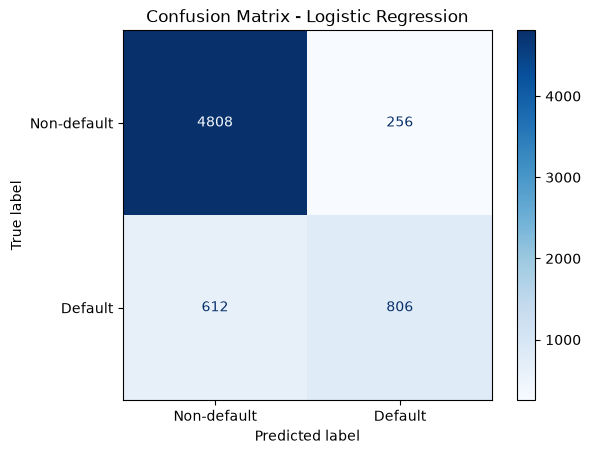

In [242]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Non-default", "Default"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

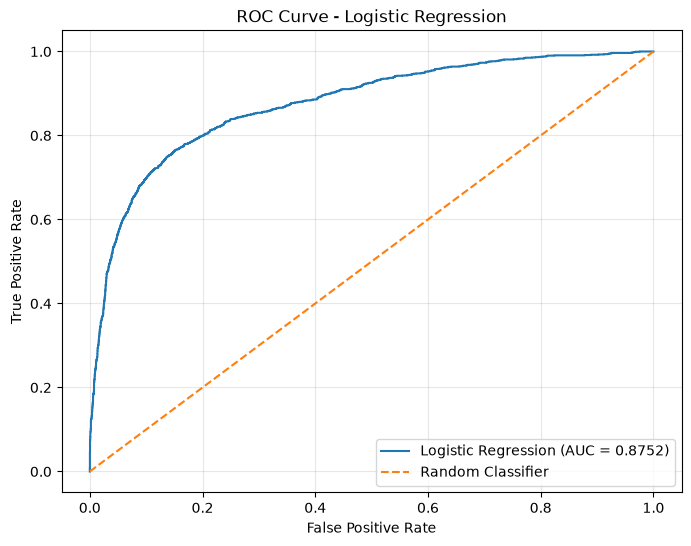

In [243]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Calculate AUC
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

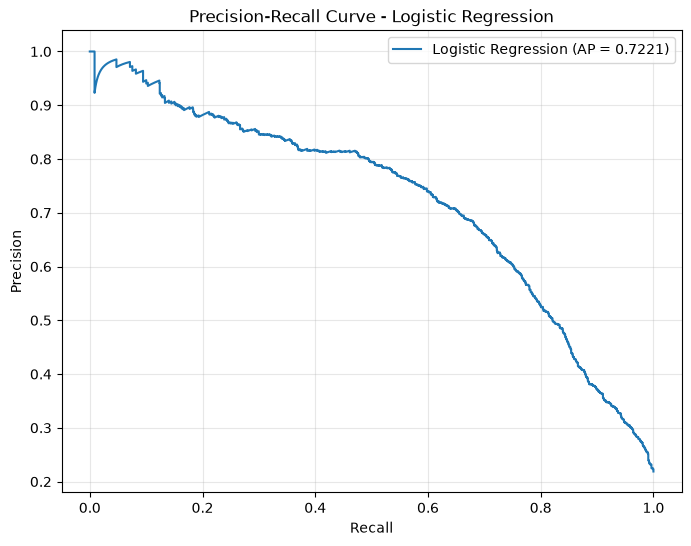

Average Precision: 0.7221


In [244]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision-recall values
precision, recall, thresholds_pr = precision_recall_curve(
    y_test,
    y_pred_proba
)

# Calculate Average Precision
avg_precision = average_precision_score(
    y_test,
    y_pred_proba
)

# Plot Precision-Recall curve
plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Logistic Regression (AP = {avg_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("Average Precision:", round(avg_precision, 4))

In [245]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    
    y_pred_threshold = (y_pred_proba >= threshold).astype(int)
    
    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)
    
    threshold_results.append({
        "threshold": threshold,
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1_score": round(f1, 4)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,threshold,precision,recall,f1_score
0,0.30,0.6149,0.7377,0.6707
1,0.35,0.6600,0.7010,0.6799
2,0.40,0.6945,0.6622,0.6780
3,0.45,0.7279,0.6150,0.6667
4,0.50,0.7589,0.5684,0.6500
5,0.55,0.7884,0.5176,0.6249
6,0.60,0.8154,0.4704,0.5966
7,0.65,0.8154,0.3893,0.5270
8,0.70,0.8415,0.3371,0.4814


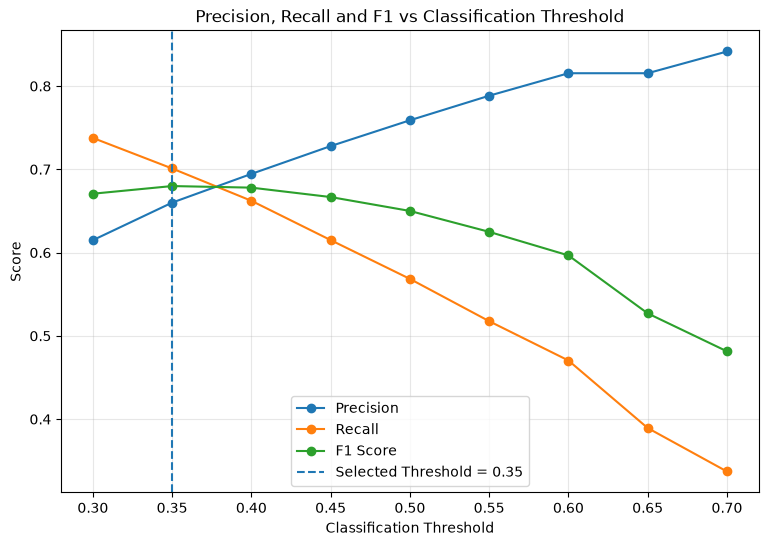

In [246]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    x=0.35,
    linestyle="--",
    label="Selected Threshold = 0.35"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Classification Threshold")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [247]:
# Selected threshold for credit-risk prediction
selected_threshold = 0.35

# Generate predictions using the selected threshold
y_pred_tuned = (
    y_pred_proba >= selected_threshold
).astype(int)

print("Selected Threshold:", selected_threshold)
print("First 10 tuned predictions:", y_pred_tuned[:10])

Selected Threshold: 0.35
First 10 tuned predictions: [0 0 1 0 1 0 1 0 0 0]


In [248]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)

print("Tuned Logistic Regression Performance")
print("--------------------------------------")
print("Threshold :", selected_threshold)
print("Accuracy  :", round(tuned_accuracy, 4))
print("Precision :", round(tuned_precision, 4))
print("Recall    :", round(tuned_recall, 4))
print("F1 Score  :", round(tuned_f1, 4))
print("ROC-AUC   :", round(roc_auc, 4))

Tuned Logistic Regression Performance
--------------------------------------
Threshold : 0.35
Accuracy  : 0.8556
Precision : 0.66
Recall    : 0.701
F1 Score  : 0.6799
ROC-AUC   : 0.8752


In [249]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print("Tuned Confusion Matrix:")
print(cm_tuned)

tn_tuned, fp_tuned, fn_tuned, tp_tuned = cm_tuned.ravel()

print("\nTrue Negatives :", tn_tuned)
print("False Positives:", fp_tuned)
print("False Negatives:", fn_tuned)
print("True Positives :", tp_tuned)

Tuned Confusion Matrix:
[[4552  512]
 [ 424  994]]

True Negatives : 4552
False Positives: 512
False Negatives: 424
True Positives : 994


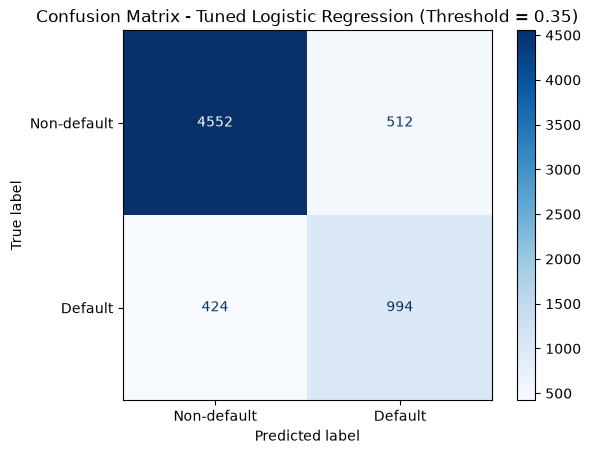

In [250]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Non-default", "Default"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Tuned Logistic Regression (Threshold = 0.35)")
plt.show()

In [251]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Baseline (0.50)": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],
    "Tuned (0.35)": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        roc_auc
    ]
})

comparison["Change"] = (
    comparison["Tuned (0.35)"] -
    comparison["Baseline (0.50)"]
)

comparison.round(4)

,Metric,Baseline (0.50),Tuned (0.35),Change
0,Accuracy,0.8661,0.8556,-0.0105
1,Precision,0.8415,0.6600,-0.1815
2,Recall,0.3371,0.7010,0.3639
3,F1 Score,0.4814,0.6799,0.1985
4,ROC-AUC,0.8752,0.8752,0.0000


In [252]:
# Recalculate baseline metrics at threshold = 0.50

baseline_threshold = 0.50

y_pred_baseline = (
    y_pred_proba >= baseline_threshold
).astype(int)

baseline_accuracy = accuracy_score(
    y_test,
    y_pred_baseline
)

baseline_precision = precision_score(
    y_test,
    y_pred_baseline
)

baseline_recall = recall_score(
    y_test,
    y_pred_baseline
)

baseline_f1 = f1_score(
    y_test,
    y_pred_baseline
)

baseline_roc_auc = roc_auc_score(
    y_test,
    y_pred_proba
)

print("Baseline Logistic Regression")
print("----------------------------")
print("Threshold :", baseline_threshold)
print("Accuracy  :", round(baseline_accuracy, 4))
print("Precision :", round(baseline_precision, 4))
print("Recall    :", round(baseline_recall, 4))
print("F1 Score  :", round(baseline_f1, 4))
print("ROC-AUC   :", round(baseline_roc_auc, 4))

Baseline Logistic Regression
----------------------------
Threshold : 0.5
Accuracy  : 0.8661
Precision : 0.7589
Recall    : 0.5684
F1 Score  : 0.65
ROC-AUC   : 0.8752


In [253]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Baseline (0.50)": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc
    ],
    "Tuned (0.35)": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        roc_auc
    ]
})

comparison["Change"] = (
    comparison["Tuned (0.35)"] -
    comparison["Baseline (0.50)"]
)

comparison.round(4)

,Metric,Baseline (0.50),Tuned (0.35),Change
0,Accuracy,0.8661,0.8556,-0.0105
1,Precision,0.7589,0.6600,-0.0989
2,Recall,0.5684,0.7010,0.1326
3,F1 Score,0.6500,0.6799,0.0299
4,ROC-AUC,0.8752,0.8752,0.0000


In [254]:
# Get feature names after preprocessing

feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get logistic regression coefficients

coefficients = logistic_model.named_steps[
    "classifier"
].coef_[0]

# Create feature importance dataframe

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Add absolute coefficient for ranking

feature_importance["abs_coefficient"] = (
    feature_importance["coefficient"].abs()
)

# Sort by importance

feature_importance = feature_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

feature_importance.head(20)

,feature,coefficient,abs_coefficient
23,cat__loan_grade_G,2.755219,2.755219
17,cat__loan_grade_A,-1.769328,1.769328
9,cat__person_home_ownership_OWN,-1.751158,1.751158
18,cat__loan_grade_B,-1.715785,1.715785
19,cat__loan_grade_C,-1.600181,1.600181
22,cat__loan_grade_F,0.912972,0.912972
4,num__loan_percent_income,0.874538,0.874538
10,cat__person_home_ownership_RENT,0.782814,0.782814
16,cat__loan_intent_VENTURE,-0.705693,0.705693
6,num__person_income_log,-0.659761,0.659761


In [255]:
# Get feature names after preprocessing

feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get logistic regression coefficients

coefficients = logistic_model.named_steps[
    "classifier"
].coef_[0]

# Create feature importance dataframe

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Add absolute coefficient for ranking

feature_importance["abs_coefficient"] = (
    feature_importance["coefficient"].abs()
)

# Sort by importance

feature_importance = feature_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

feature_importance.head(20)

,feature,coefficient,abs_coefficient
23,cat__loan_grade_G,2.755219,2.755219
17,cat__loan_grade_A,-1.769328,1.769328
9,cat__person_home_ownership_OWN,-1.751158,1.751158
18,cat__loan_grade_B,-1.715785,1.715785
19,cat__loan_grade_C,-1.600181,1.600181
22,cat__loan_grade_F,0.912972,0.912972
4,num__loan_percent_income,0.874538,0.874538
10,cat__person_home_ownership_RENT,0.782814,0.782814
16,cat__loan_intent_VENTURE,-0.705693,0.705693
6,num__person_income_log,-0.659761,0.659761


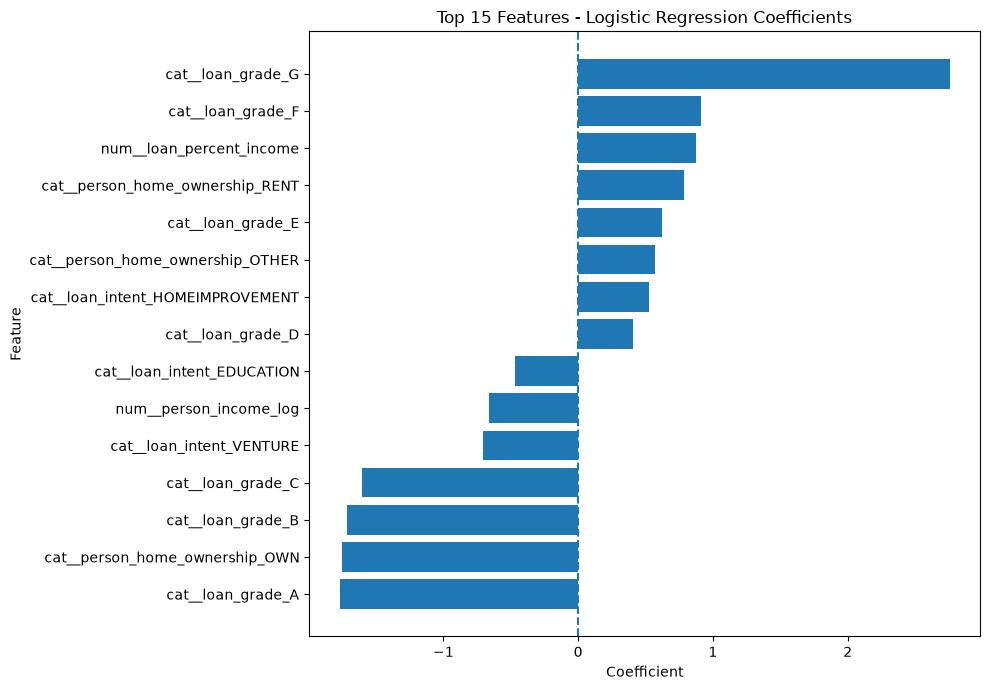

In [256]:
# Top 15 features by absolute coefficient

top_features = (
    feature_importance
    .head(15)
    .sort_values("coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["coefficient"]
)

plt.axvline(0, linestyle="--")

plt.title("Top 15 Features - Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [257]:
#Random Forest model

In [291]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully.")


ImportError: DLL load failed while importing _kd_tree: An Application Control policy has blocked this file.

In [ ]:

# Create the Random Forest pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully.")


Random Forest pipeline created successfully.


In [ ]:

# Train the Random Forest model

random_forest_model.fit(X_train_model, y_train)

print("Random Forest model trained successfully.")


Random Forest model trained successfully.


In [292]:

# Predict loan status on the test dataset

y_pred_rf = random_forest_model.predict(X_test_model)

# Predict probability of default (class 1)

y_pred_proba_rf = random_forest_model.predict_proba(
    X_test_model
)[:, 1]

print("Random Forest predictions generated successfully.")
print("First 10 predictions:", y_pred_rf[:10])
print("First 10 default probabilities:", y_pred_proba_rf[:10].round(4))


NameError: name 'random_forest_model' is not defined

In [260]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_pred_proba_rf)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))


NameError: name 'y_pred_rf' is not defined

In [261]:

# Compare all three model configurations

model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Logistic Regression (0.50)": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc
    ],
    "Logistic Regression (0.35)": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        roc_auc
    ],
    "Random Forest (0.50)": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ]
})

model_comparison.round(4)


NameError: name 'rf_accuracy' is not defined

In [262]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()

print("Random Forest Confusion Matrix:")
print(cm_rf)

print("\nTrue Negatives :", tn_rf)
print("False Positives:", fp_rf)
print("False Negatives:", fn_rf)
print("True Positives :", tp_rf)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Non-default", "Default"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Random Forest (Threshold = 0.50)")
plt.show()


NameError: name 'y_pred_rf' is not defined

In [263]:

# Evaluate Random Forest at different thresholds

threshold_results_rf = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:

    y_pred_threshold_rf = (
        y_pred_proba_rf >= threshold
    ).astype(int)

    precision_rf = precision_score(
        y_test, y_pred_threshold_rf, zero_division=0
    )

    recall_rf = recall_score(
        y_test, y_pred_threshold_rf, zero_division=0
    )

    f1_rf = f1_score(
        y_test, y_pred_threshold_rf, zero_division=0
    )

    threshold_results_rf.append({
        "threshold": threshold,
        "precision": round(precision_rf, 4),
        "recall": round(recall_rf, 4),
        "f1_score": round(f1_rf, 4)
    })

threshold_df_rf = pd.DataFrame(threshold_results_rf)

threshold_df_rf


NameError: name 'y_pred_proba_rf' is not defined

In [264]:

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df_rf["threshold"],
    threshold_df_rf["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df_rf["threshold"],
    threshold_df_rf["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df_rf["threshold"],
    threshold_df_rf["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    0.60,
    linestyle="--",
    label="Provisional threshold = 0.60"
)

plt.title("Random Forest: Precision, Recall and F1 vs Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.xticks(threshold_df_rf["threshold"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


NameError: name 'threshold_df_rf' is not defined

<Figure size 1000x600 with 0 Axes>

In [265]:

# Select the provisional threshold
selected_threshold_rf = 0.60

# Generate threshold-adjusted predictions
y_pred_tuned_rf = (
    y_pred_proba_rf >= selected_threshold_rf
).astype(int)

print("Selected Random Forest threshold:", selected_threshold_rf)
print("First 10 tuned predictions:", y_pred_tuned_rf[:10])


NameError: name 'y_pred_proba_rf' is not defined

In [266]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Evaluate predictions at threshold 0.60
rf_tuned_accuracy = accuracy_score(y_test, y_pred_tuned_rf)
rf_tuned_precision = precision_score(
    y_test, y_pred_tuned_rf, zero_division=0
)
rf_tuned_recall = recall_score(y_test, y_pred_tuned_rf)
rf_tuned_f1 = f1_score(y_test, y_pred_tuned_rf)

# ROC-AUC is threshold-independent
rf_tuned_roc_auc = roc_auc_score(y_test, y_pred_proba_rf)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("Threshold :", selected_threshold_rf)
print("Accuracy  :", round(rf_tuned_accuracy, 4))
print("Precision :", round(rf_tuned_precision, 4))
print("Recall    :", round(rf_tuned_recall, 4))
print("F1 Score  :", round(rf_tuned_f1, 4))
print("ROC-AUC   :", round(rf_tuned_roc_auc, 4))


NameError: name 'y_pred_tuned_rf' is not defined

In [267]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf_tuned = confusion_matrix(y_test, y_pred_tuned_rf)

tn_rf, fp_rf, fn_rf, tp_rf = cm_rf_tuned.ravel()

print("Tuned Random Forest Confusion Matrix:")
print(cm_rf_tuned)

print("\nTrue Negatives :", tn_rf)
print("False Positives:", fp_rf)
print("False Negatives:", fn_rf)
print("True Positives :", tp_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_tuned,
    display_labels=["Non-default", "Default"]
).plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix - Threshold 0.60")
plt.tight_layout()
plt.show()


NameError: name 'y_pred_tuned_rf' is not defined

In [268]:

model_comparison_final = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Logistic Regression (0.50)": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc
    ],
    "Logistic Regression (0.35)": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        roc_auc
    ],
    "Random Forest (0.50)": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc
    ],
    "Random Forest (0.60)": [
        rf_tuned_accuracy,
        rf_tuned_precision,
        rf_tuned_recall,
        rf_tuned_f1,
        rf_tuned_roc_auc
    ]
})

model_comparison_final.round(4)


NameError: name 'rf_accuracy' is not defined

In [269]:

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest from the pipeline
rf_classifier = random_forest_model.named_steps["classifier"]

# Get the feature names after preprocessing
feature_names = (
    random_forest_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract feature importance scores
rf_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

# Sort from highest to lowest
rf_importance = rf_importance.sort_values(
    by="importance",
    ascending=False
)

print("Top 15 Random Forest Features:")
display(rf_importance.head(15))

# Visualize the top 15 features
top_features = rf_importance.head(15).sort_values(
    by="importance"
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance"])
plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


NameError: name 'random_forest_model' is not defined

In [270]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate the fitted Random Forest pipeline
perm_result = permutation_importance(
    random_forest_model,
    X_test_model,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "feature": X_test_model.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(permutation_df.head(15))


ImportError: DLL load failed while importing _kd_tree: An Application Control policy has blocked this file.

In [ ]:

print("Random Forest pipeline:", random_forest_model)
print("Selected threshold:", selected_threshold_rf)
print("Test ROC-AUC:", round(rf_tuned_roc_auc, 4))
print("Test F1-score:", round(rf_tuned_f1, 4))


Random Forest pipeline: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['person_age',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length',
                                                   'person_income_log']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
  

In [ ]:

import joblib
import os

# Create a folder to store the trained model
os.makedirs("models", exist_ok=True)

# Save the complete pipeline and classification threshold
model_artifact = {
    "model": random_forest_model,
    "threshold": selected_threshold_rf
}

joblib.dump(
    model_artifact,
    "models/credit_risk_random_forest.joblib"
)

print("Model saved successfully!")
print("File: models/credit_risk_random_forest.joblib")


Model saved successfully!
File: models/credit_risk_random_forest.joblib


In [ ]:

# Load the saved model artifact
loaded_artifact = joblib.load(
    "models/credit_risk_random_forest.joblib"
)

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

# Generate default probabilities
loaded_probabilities = loaded_model.predict_proba(
    X_test_model
)[:, 1]

# Apply the saved threshold
loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

print("Model loaded successfully!")
print("Saved threshold:", loaded_threshold)

print(
    "Predictions match original:",
    (loaded_predictions == y_pred_tuned_rf).all()
)


Model loaded successfully!
Saved threshold: 0.6
Predictions match original: True


In [ ]:

import numpy as np
import pandas as pd

def predict_credit_risk(customer_data):
    # Copy input to avoid modifying the original dictionary
    customer_df = pd.DataFrame([customer_data]).copy()

    # Create the engineered feature automatically
    customer_df["person_income_log"] = np.log1p(
        customer_df["person_income"]
    )

    # Predict probability of default
    default_probability = loaded_model.predict_proba(
        customer_df
    )[0, 1]

    # Apply saved classification threshold
    prediction = int(
        default_probability >= loaded_threshold
    )

    return {
        "default_probability": round(
            float(default_probability) * 100, 2
        ),
        "prediction": prediction,
        "risk_class": (
            "Default Risk Detected"
            if prediction == 1
            else "No Default Risk Flag"
        ),
        "threshold": loaded_threshold
    }

print("Improved prediction function created.")


Improved prediction function created.


In [ ]:

sample_customer = {
    "person_age": 30,
    "person_income": 60000,
    "person_home_ownership": "RENT",
    "person_emp_length": 5,
    "loan_intent": "PERSONAL",
    "loan_grade": "B",
    "loan_amnt": 10000,
    "loan_int_rate": 11.5,
    "loan_percent_income": 0.167,
    "cb_person_default_on_file": "N",
    "cb_person_cred_hist_length": 7,
}

result = predict_credit_risk(sample_customer)

print("Credit Risk Prediction")
print("----------------------")
print("Default probability:", result["default_probability"], "%")
print("Prediction:", result["prediction"])
print("Risk classification:", result["risk_class"])
print("Threshold:", result["threshold"])


Credit Risk Prediction
----------------------
Default probability: 12.5 %
Prediction: 0
Risk classification: No Default Risk Flag
Threshold: 0.6


In [ ]:

# Test the model with multiple customer profiles

test_customers = [
    {
        "person_age": 25,
        "person_income": 35000,
        "person_home_ownership": "RENT",
        "person_emp_length": 2,
        "loan_intent": "PERSONAL",
        "loan_grade": "C",
        "loan_amnt": 12000,
        "loan_int_rate": 14.5,
        "loan_percent_income": 0.343,
        "cb_person_default_on_file": "Y",
        "cb_person_cred_hist_length": 3
    },
    {
        "person_age": 40,
        "person_income": 100000,
        "person_home_ownership": "OWN",
        "person_emp_length": 15,
        "loan_intent": "HOMEIMPROVEMENT",
        "loan_grade": "A",
        "loan_amnt": 10000,
        "loan_int_rate": 8.5,
        "loan_percent_income": 0.10,
        "cb_person_default_on_file": "N",
        "cb_person_cred_hist_length": 15
    }
]

for i, customer in enumerate(test_customers, start=1):
    result = predict_credit_risk(customer)

    print(f"\nCustomer {i}")
    print("-" * 25)
    print("Default probability:", result["default_probability"], "%")
    print("Prediction:", result["prediction"])
    print("Risk classification:", result["risk_class"])



Customer 1
-------------------------
Default probability: 96.0 %
Prediction: 1
Risk classification: Default Risk Detected

Customer 2
-------------------------
Default probability: 2.5 %
Prediction: 0
Risk classification: No Default Risk Flag


In [271]:

try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")


XGBoost version: 3.4.1


In [272]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

# Create the XGBoost pipeline
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("XGBoost pipeline created successfully.")


XGBoost pipeline created successfully.


In [273]:

# Train XGBoost
xgb_model.fit(X_train_model, y_train)

print("XGBoost model trained successfully.")


XGBoost model trained successfully.


In [274]:

# Predict loan status on the test dataset
y_pred_xgb = xgb_model.predict(X_test_model)

# Predict probability of default (class 1)
y_pred_proba_xgb = xgb_model.predict_proba(
    X_test_model
)[:, 1]

print("XGBoost predictions generated successfully.")
print("First 10 predictions:", y_pred_xgb[:10])
print(
    "First 10 default probabilities:",
    y_pred_proba_xgb[:10].round(4)
)


XGBoost predictions generated successfully.
First 10 predictions: [0 0 0 0 1 0 1 0 0 0]
First 10 default probabilities: [0.1268 0.2064 0.0519 0.0504 0.988  0.0019 0.9724 0.0305 0.0014 0.0065]


In [275]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(
    y_test, y_pred_xgb, zero_division=0
)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_roc_auc = roc_auc_score(y_test, y_pred_proba_xgb)

print("XGBoost Performance (Threshold = 0.50)")
print("--------------------------------------")
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1 Score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_roc_auc, 4))


XGBoost Performance (Threshold = 0.50)
--------------------------------------
Accuracy : 0.9397
Precision: 0.9795
Recall   : 0.7398
F1 Score : 0.8429
ROC-AUC  : 0.951


XGBoost Confusion Matrix:
[[5042   22]
 [ 369 1049]]

True Negatives : 5042
False Positives: 22
False Negatives: 369
True Positives : 1049


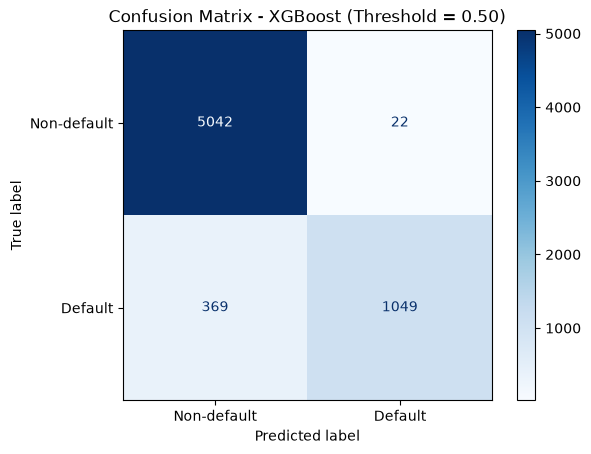

In [276]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print("XGBoost Confusion Matrix:")
print(cm_xgb)

tn_xgb, fp_xgb, fn_xgb, tp_xgb = cm_xgb.ravel()

print("\nTrue Negatives :", tn_xgb)
print("False Positives:", fp_xgb)
print("False Negatives:", fn_xgb)
print("True Positives :", tp_xgb)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Non-default", "Default"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - XGBoost (Threshold = 0.50)")
plt.show()


In [277]:

# Test different classification thresholds for XGBoost

thresholds_xgb = [
    0.30, 0.35, 0.40, 0.45, 0.50,
    0.55, 0.60, 0.65, 0.70
]

threshold_results_xgb = []

for threshold in thresholds_xgb:

    # Convert probabilities into binary predictions
    y_pred_threshold_xgb = (
        y_pred_proba_xgb >= threshold
    ).astype(int)

    precision_xgb = precision_score(
        y_test, y_pred_threshold_xgb, zero_division=0
    )

    recall_xgb = recall_score(
        y_test, y_pred_threshold_xgb, zero_division=0
    )

    f1_xgb = f1_score(
        y_test, y_pred_threshold_xgb, zero_division=0
    )

    threshold_results_xgb.append({
        "threshold": threshold,
        "precision": round(precision_xgb, 4),
        "recall": round(recall_xgb, 4),
        "f1_score": round(f1_xgb, 4)
    })

threshold_df_xgb = pd.DataFrame(threshold_results_xgb)

display(threshold_df_xgb)


,threshold,precision,recall,f1_score
0,0.30,0.9002,0.7828,0.8374
1,0.35,0.9315,0.7673,0.8415
2,0.40,0.9494,0.7539,0.8404
3,0.45,0.9662,0.7461,0.8420
4,0.50,0.9795,0.7398,0.8429
5,0.55,0.9905,0.7320,0.8418
6,0.60,0.9904,0.7250,0.8371
7,0.65,0.9942,0.7221,0.8366
8,0.70,0.9941,0.7172,0.8333


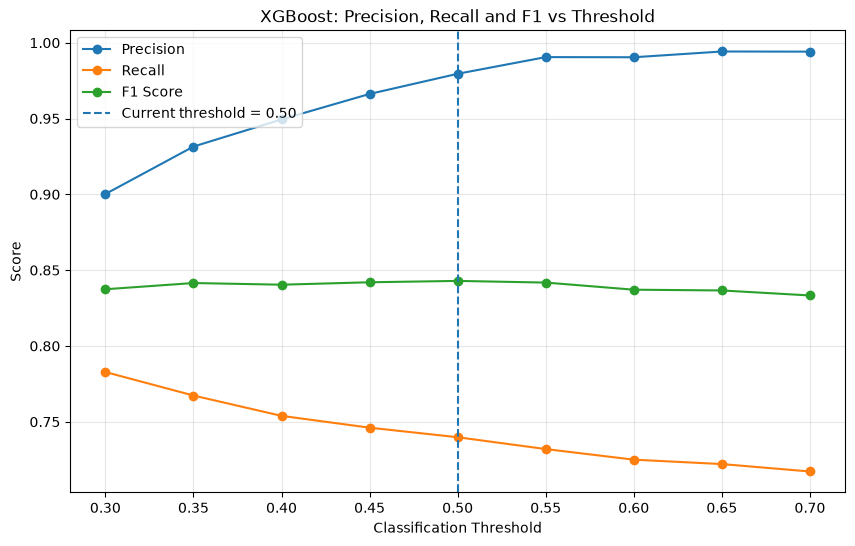

In [278]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df_xgb["threshold"],
    threshold_df_xgb["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df_xgb["threshold"],
    threshold_df_xgb["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df_xgb["threshold"],
    threshold_df_xgb["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Current threshold = 0.50"
)

plt.title("XGBoost: Precision, Recall and F1 vs Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.xticks(thresholds_xgb)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


Final XGBoost Evaluation
------------------------------
Threshold : 0.5
Accuracy  : 0.9397
Precision : 0.9795
Recall    : 0.7398
F1 Score  : 0.8429
ROC-AUC   : 0.951

Confusion Matrix:
[[5042   22]
 [ 369 1049]]


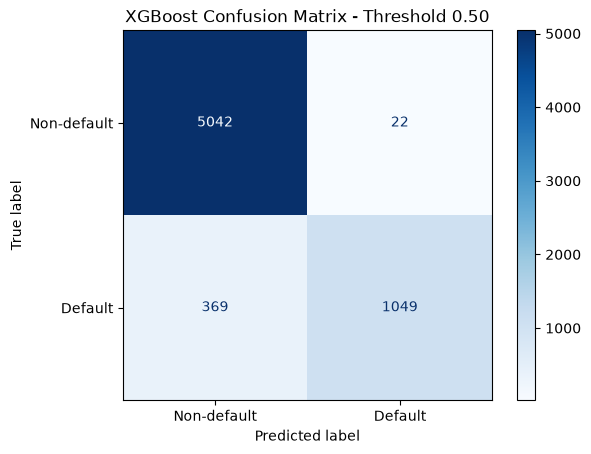

In [279]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Select the provisional threshold
selected_threshold_xgb = 0.50

# Generate threshold-adjusted predictions
y_pred_tuned_xgb = (
    y_pred_proba_xgb >= selected_threshold_xgb
).astype(int)

# Evaluate the model
xgb_tuned_accuracy = accuracy_score(
    y_test, y_pred_tuned_xgb
)

xgb_tuned_precision = precision_score(
    y_test, y_pred_tuned_xgb, zero_division=0
)

xgb_tuned_recall = recall_score(
    y_test, y_pred_tuned_xgb, zero_division=0
)

xgb_tuned_f1 = f1_score(
    y_test, y_pred_tuned_xgb, zero_division=0
)

# ROC-AUC uses probabilities, not thresholded predictions
xgb_tuned_roc_auc = roc_auc_score(
    y_test, y_pred_proba_xgb
)

print("Final XGBoost Evaluation")
print("-" * 30)
print("Threshold :", selected_threshold_xgb)
print("Accuracy  :", round(xgb_tuned_accuracy, 4))
print("Precision :", round(xgb_tuned_precision, 4))
print("Recall    :", round(xgb_tuned_recall, 4))
print("F1 Score  :", round(xgb_tuned_f1, 4))
print("ROC-AUC   :", round(xgb_tuned_roc_auc, 4))

# Confusion matrix
cm_xgb = confusion_matrix(
    y_test, y_pred_tuned_xgb
)

print("\nConfusion Matrix:")
print(cm_xgb)

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Non-default", "Default"]
).plot(cmap="Blues")

plt.title("XGBoost Confusion Matrix - Threshold 0.50")
plt.show()


In [288]:

model_comparison_final = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Logistic Regression (0.50)": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc
    ],
    "Random Forest (0.60)": [
        rf_tuned_accuracy,
        rf_tuned_precision,
        rf_tuned_recall,
        rf_tuned_f1,
        rf_tuned_roc_auc
    ],
    "XGBoost (0.50)": [
        xgb_tuned_accuracy,
        xgb_tuned_precision,
        xgb_tuned_recall,
        xgb_tuned_f1,
        xgb_tuned_roc_auc
    ]
})

display(model_comparison_final.round(4))


NameError: name 'rf_tuned_accuracy' is not defined

In [281]:

import joblib
from pathlib import Path

# Project root: parent of the notebooks folder
project_root = Path.cwd().parent

# Root models directory
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Store model and its classification threshold together
xgb_artifact = {
    "model": xgb_model,
    "threshold": selected_threshold_xgb
}

xgb_model_path = models_dir / "credit_risk_xgboost.joblib"

joblib.dump(xgb_artifact, xgb_model_path)

print("XGBoost model saved successfully!")
print("Saved path:", xgb_model_path.resolve())
print("Threshold:", selected_threshold_xgb)


XGBoost model saved successfully!
Saved path: E:\AI-Credit-Risk-Prediction-System\models\credit_risk_xgboost.joblib
Threshold: 0.5


In [282]:

loaded_xgb_artifact = joblib.load(xgb_model_path)

loaded_xgb_model = loaded_xgb_artifact["model"]
loaded_xgb_threshold = loaded_xgb_artifact["threshold"]

loaded_xgb_probabilities = loaded_xgb_model.predict_proba(
    X_test_model
)[:, 1]

loaded_xgb_predictions = (
    loaded_xgb_probabilities >= loaded_xgb_threshold
).astype(int)

print("Model loaded successfully!")
print("Saved threshold:", loaded_xgb_threshold)
print(
    "Predictions match original:",
    (loaded_xgb_predictions == y_pred_tuned_xgb).all()
)


Model loaded successfully!
Saved threshold: 0.5
Predictions match original: True


In [283]:

import sys
import importlib
from pathlib import Path

project_root = Path.cwd().parent
src_path = str(project_root / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

import predict
importlib.reload(predict)

print("Module location:", predict.__file__)
print("Available prediction function:",
      hasattr(predict, "predict_credit_risk"))
print("Functions in module:",
      [name for name in dir(predict) if "predict" in name])


Module location: e:\AI-Credit-Risk-Prediction-System\src\predict.py
Available prediction function: True
Functions in module: ['predict_credit_risk']


In [284]:

from predict import predict_credit_risk

sample_customer = {
    "person_age": 30,
    "person_income": 60000,
    "person_home_ownership": "RENT",
    "person_emp_length": 5,
    "loan_intent": "PERSONAL",
    "loan_grade": "B",
    "loan_amnt": 10000,
    "loan_int_rate": 11.5,
    "loan_percent_income": 0.167,
    "cb_person_default_on_file": "N",
    "cb_person_cred_hist_length": 7
}

result = predict_credit_risk(sample_customer)

print("Credit Risk Prediction")
print("----------------------")
print("Default probability:", result["default_probability"], "%")
print("Prediction:", result["prediction"])
print("Risk classification:", result["risk_class"])
print("Threshold:", result["threshold"])


Credit Risk Prediction
----------------------
Default probability: 3.41 %
Prediction: 0
Risk classification: No Default Risk Flag
Threshold: 0.5


In [285]:

import importlib
import predict

importlib.reload(predict)

predict_credit_risk = predict.predict_credit_risk

print("Prediction module reloaded successfully.")


Prediction module reloaded successfully.


In [286]:

sample_customer = {
    "person_age": 30,
    "person_income": 60000,
    "person_home_ownership": "RENT",
    "person_emp_length": 5,
    "loan_intent": "PERSONAL",
    "loan_grade": "B",
    "loan_amnt": 10000,
    "loan_int_rate": 11.5,
    "loan_percent_income": 0.167,
    "cb_person_default_on_file": "N",
    "cb_person_cred_hist_length": 7,
}

result = predict_credit_risk(sample_customer)

print("Credit Risk Prediction")
print("----------------------")
print("Default probability:", result["default_probability"], "%")
print("Prediction:", result["prediction"])
print("Risk classification:", result["risk_class"])
print("Threshold:", result["threshold"])


Credit Risk Prediction
----------------------
Default probability: 3.41 %
Prediction: 0
Risk classification: No Default Risk Flag
Threshold: 0.5


In [287]:

invalid_customer = sample_customer.copy()
invalid_customer["person_income"] = -5000

try:
    predict_credit_risk(invalid_customer)
except ValueError as error:
    print("Validation working:", error)


Validation working: person_income must be greater than zero.


In [293]:
# Step 3D: Test existing input validations

test_cases = [
    ("Missing field", {"person_income": None}, "missing"),
    ("Negative income", {"person_income": -5000}, "income"),
    ("Zero loan amount", {"loan_amnt": 0}, "loan_amnt"),
    ("Invalid loan grade", {"loan_grade": "Z"}, "loan_grade"),
    ("Negative employment", {"person_emp_length": -1}, "employment"),
]

for test_name, changes, expected_error in test_cases:
    test_customer = sample_customer.copy()

    if expected_error == "missing":
        test_customer.pop("person_income")
    else:
        test_customer.update(changes)

    try:
        predict_credit_risk(test_customer)
        print(f"FAIL: {test_name} was not rejected.")

    except (ValueError, TypeError) as error:
        print(f"PASS: {test_name} -> {error}")

PASS: Missing field -> Missing required fields: ['person_income']
PASS: Negative income -> person_income must be greater than zero.
PASS: Zero loan amount -> loan_amnt must be greater than zero.
PASS: Invalid loan grade -> Invalid loan_grade: Z. Allowed values: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
PASS: Negative employment -> person_emp_length cannot be negative.
